# Landsat 8/9 OLI Mapping of Fe³⁺ and OH/SO₄-bearing Mineral Proxies over Mine Waste
## Tharsis-Lagunazo, Iberian Pyrite Belt, SW Spain

## 0 · Environment check and plotting style

In [ ]:
import os, sys, importlib
from importlib import metadata as _metadata

REQUIRED = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "sklearn": "scikit-learn",
            "matplotlib": "matplotlib", "rasterio": "rasterio"}
OPTIONAL = {"contextily": "contextily"}                        # satellite basemap only
IS_CONDA = os.path.isdir(os.path.join(sys.prefix, "conda-meta"))

def _check_packages():
    missing, broken = [], []
    for mod, pkg in {**REQUIRED, **OPTIONAL}.items():
        required = mod in REQUIRED
        try:
            version = getattr(importlib.import_module(mod), "__version__", "")
            print(f"  ok        {mod:<11} {version}")
        except ModuleNotFoundError as err:
            top = (err.name or "").split(".")[0]
            if err.name == mod:                                 # package not installed
                print(f"  {'MISSING' if required else 'absent':<9} {mod}"
                      + ("" if required else "   (optional: maps are drawn without a basemap)"))
                if required:
                    missing.append(pkg)
            elif top != mod and top in REQUIRED:                # fails only because another package is broken
                print(f"  BROKEN    {mod:<11} because {top} is broken (fixed together with {top})")
            else:                                               # installed, but a file inside it is missing
                print(f"  BROKEN    {mod:<11} {err}")
                if required:
                    broken.append(pkg)
        except Exception as err:                                # installed, but fails while importing
            print(f"  BROKEN    {mod:<11} {type(err).__name__}: {err}")
            if required:
                broken.append(pkg)
    return missing, broken

def _pinned(pkg):
    try:
        return f'"{pkg}=={_metadata.version(pkg)}"'              # reinstall the version already recorded
    except Exception:
        return pkg

def _fix_instructions(missing, broken, is_conda):
    exe = f'"{sys.executable}"'
    repair = f"--force-reinstall --no-deps {' '.join(_pinned(p) for p in broken)}" if broken else ""
    add = [p for p in missing if not (is_conda and p == "rasterio")]
    lines = ["This kernel's Python environment is incomplete.",
             "Fix from the notebook: RESTART THE KERNEL, then run ONLY a new first cell containing:"]
    if repair:
        lines.append(f"    %pip install {repair}")
    if add:
        lines.append(f"    %{'conda install -y' if is_conda else 'pip install'} {' '.join(add)}")
    lines += ["  then restart the kernel again and run the notebook from the top.",
              "If that reports 'Access is denied': close VS Code and run the same in a terminal"
              + (" (Anaconda Prompt, as administrator)" if is_conda else "") + ":"]
    if repair:
        lines.append(f"    {exe} -m pip install {repair}")
    if add:
        lines.append(f"    {'conda install -y -p ' + chr(34) + sys.prefix + chr(34) if is_conda else exe + ' -m pip install'} {' '.join(add)}")
    if is_conda and "rasterio" in missing:
        lines += ["rasterio (with GDAL) is safest in its own conda-forge environment:",
                  "    conda create -y -n landsat -c conda-forge python=3.12 numpy pandas scipy scikit-learn "
                  "matplotlib rasterio contextily ipykernel",
                  "  then select the 'landsat' kernel for this notebook."]
    return "\n".join(lines)

print(f"Python {sys.version.split()[0]}  ·  {sys.executable}  ·  {'conda' if IS_CONDA else 'pip'} environment")
_missing, _broken = _check_packages()
if _missing or _broken:
    raise RuntimeError(_fix_instructions(_missing, _broken, IS_CONDA))
print("Environment OK")

# Core scientific stack
import re, math, textwrap, zipfile
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.patches import FancyArrow, Rectangle
from matplotlib.ticker import FuncFormatter, MaxNLocator

import rasterio
from rasterio.features import geometry_mask
from rasterio.mask import mask as rio_mask
from rasterio.warp import transform_geom, reproject, Resampling
from rasterio.warp import transform as warp_transform
from rasterio.windows import from_bounds
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

FIG_DPI      = 400             # export resolution for every PNG
NODATA_COLOR = "#f2f1ee"       # neutral fill for masked pixels in panel figures

# Chart colours: validated categorical order; text stays in ink colours, never series colours
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
DIVERGING = LinearSegmentedColormap.from_list("blue_grey_red", ["#2a78d6", "#f0efec", "#e34948"])
SEQ_BLUE  = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#2a78d6", "#0d366b"])

plt.rcParams.update({
    "figure.dpi"         : 120,
    "savefig.dpi"        : FIG_DPI,
    "savefig.bbox"       : "tight",
    "savefig.pad_inches" : 0.05,
    "figure.facecolor"   : "white",
    "savefig.facecolor"  : "white",
    "font.family"        : "DejaVu Sans",
    "font.size"          : 10,
    "axes.titlesize"     : 12,
    "axes.titleweight"   : "bold",
    "axes.labelsize"     : 10,
    "axes.linewidth"     : 0.9,
    "axes.edgecolor"     : "0.12",
    "xtick.labelsize"    : 8,
    "ytick.labelsize"    : 8,
    "xtick.direction"    : "out",
    "ytick.direction"    : "out",
    "xtick.major.size"   : 3.5,
    "ytick.major.size"   : 3.5,
    "grid.color"         : GRID,
    "grid.linewidth"     : 0.6,
    "grid.linestyle"     : "-",
    "image.interpolation": "nearest",
    "legend.frameon"     : False,
    "mathtext.default"   : "regular",
})

def style_chart(ax, grid_axis="y"):
    """Recessive chart chrome: hairline solid grid, no top/right spines, ink-coloured text."""
    ax.set_axisbelow(True)
    if grid_axis:
        ax.grid(True, axis=grid_axis, color=GRID, lw=0.6)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color("#c3c2b7")
    ax.tick_params(colors=INK_2, labelcolor=INK_2)
    ax.xaxis.label.set_color(INK); ax.yaxis.label.set_color(INK)
    ax.title.set_color(INK)

print(f"Plot style set  ·  export DPI = {FIG_DPI}")

Python 3.12.3  ·  c:\anaconda3\python.exe  ·  conda environment
  ok        numpy       1.26.4
  ok        pandas      3.0.2
  ok        scipy       1.15.2
  ok        sklearn     1.6.1
  ok        matplotlib  3.10.9
  ok        rasterio    1.4.3
  ok        contextily  1.6.2
Environment OK
Plot style set  ·  export DPI = 400


## 1 · Configuration

In [ ]:
#  CONFIG
SITE_NAME = "Tharsis-Lagunazo"

# INPUT: Collection-2 Level-2 reflectance bands B1–B7 (SR_B*) plus the thermal band B10 (ST_B10)
BAND_FILES = {
    1 : "LC09_L2SP_202034_20260330_20260331_02_T1_SR_B1.TIF",   # coastal / aerosol
    2 : "LC09_L2SP_202034_20260330_20260331_02_T1_SR_B2.TIF",   # blue
    3 : "LC09_L2SP_202034_20260330_20260331_02_T1_SR_B3.TIF",   # green
    4 : "LC09_L2SP_202034_20260330_20260331_02_T1_SR_B4.TIF",   # red
    5 : "LC09_L2SP_202034_20260330_20260331_02_T1_SR_B5.TIF",   # NIR
    6 : "LC09_L2SP_202034_20260330_20260331_02_T1_SR_B6.TIF",   # SWIR-1
    7 : "LC09_L2SP_202034_20260330_20260331_02_T1_SR_B7.TIF",   # SWIR-2
    10: "LC09_L2SP_202034_20260330_20260331_02_T1_ST_B10.TIF",  # surface temperature
}
STACK_FILE  = None                  # (fallback) single multi-band stack
STACK_ORDER = [1, 2, 3, 4, 5, 6, 7, 10]

# PRODUCT SCALING (Collection-2 Level-2; USGS LSDS-1619 Table 6-1)
IS_LEVEL2_DN = True                 # raw C2 L2 DN; False if the bands are already reflectance
SR_SCALE, SR_OFFSET = 2.75e-5, -0.2
ST_SCALE, ST_OFFSET = 0.00341802, 149.0
NODATA_DN   = 0
SR_VALID_DN = (7273, 43636)         # valid SR range in DN (reflectance 0–1)

# QUALITY LAYERS: path, "auto" (look beside SR_B1) or None
QA_PIXEL_FILE      = "auto"
SR_QA_AEROSOL_FILE = "auto"
QA_MASK_BITS = {"dilated cloud": 1, "cirrus": 2, "cloud": 3, "cloud shadow": 4, "snow": 5}
MASK_HIGH_AEROSOL = True

# AREA OF INTEREST: .kmz/.kml polygon in EPSG:4326; None = full tile
AOI_KMZ    = "aoi_boundary.kmz"
AOI_BOUNDS = None                   # optional bbox in scene CRS (xmin, ymin, xmax, ymax)

# ANALYSIS MASKS
NDVI_VEG_THRESHOLD    = 0.30        # NDVI above this = vegetation
MNDWI_WATER_THRESHOLD = 0.00        # MNDWI = (B3-B6)/(B3+B6) above this = open water
DARK_SR_MIN           = 0.01        # any of B2–B7 below this = dark / shadow

# CRÓSTA (FEATURE-ORIENTED PCA)
CROSTA_STANDARDISE = True           # True = correlation-matrix PCA (as r5); False = covariance PCA
CROSTA_FE_PC = None                 # force a component (1-based) after reading the loadings
CROSTA_OH_PC = None

# K-MEANS
N_CLUSTERS        = 6
K_RANGE           = range(3, 11)
AUTO_K            = False           # True = use the k with the highest silhouette
RANDOM_STATE      = 42
USE_LST_IN_KMEANS = False

# ANOMALY THRESHOLDS AND ROBUSTNESS
SIGMA_LEVELS     = (1.0, 2.0)       # mean + k·sigma
CA_N_THRESHOLDS  = 120              # thresholds sampled for the concentration–area plot
TOP_PERCENT      = 10               # top-x % masks for method overlap (Jaccard)
NDVI_SENSITIVITY = (0.20, 0.25, 0.30, 0.35, 0.40)

# SPECTRAL LIBRARY SAM (optional)
LIBRARY_CSV          = None         # CSV with columns: mineral,B1,B2,B3,B4,B5,B6,B7
USGS_WAVELENGTH_FILE = None         # USGS splib07 wavelength file matching the spectra below
USGS_SPECTRA         = {}           # {"Jarosite": "path/to/spectrum.txt", "Goethite": "...", ...}
SAM_MAX_ANGLE        = 0.10         # radians; farther than this from every endmember = unclassified
SAM_AMBIGUITY_MARGIN = 0.02         # radians; best and second-best endmember closer than this = ambiguous

# VALIDATION (optional)
SAMPLES_CSV       = None
SAMPLE_X_COL      = "x_utm"
SAMPLE_Y_COL      = "y_utm"
SAMPLE_CRS        = "EPSG:32629"
SAMPLE_VALUE_COLS = []              # e.g. ["Fe_pct", "S_pct", "Bi_ppm", "Sb_ppm"]
SAMPLE_CLASS_COL  = None            # e.g. "jarosite_ftir" (0/1) or "domain"
SAMPLE_WINDOW     = 3               # mean of an n × n pixel window around each sample
ENMAP_RASTERS     = {}              # {"EnMAP jarosite": "path.tif"} or {"EnMAP jarosite": ("path.tif", band)}

# OUTPUT
OUTPUT_DIR = Path("work_r6")
FIG_DIR    = OUTPUT_DIR / "figures"
RASTER_DIR = OUTPUT_DIR / "rasters"
TABLE_DIR  = OUTPUT_DIR / "tables"
EXPORT_GEOTIFF = True
for _d in (FIG_DIR, RASTER_DIR, TABLE_DIR):
    _d.mkdir(parents=True, exist_ok=True)

_bands_set = bool(BAND_FILES) and all(BAND_FILES.get(b) for b in range(1, 8))
print(f"Site       : {SITE_NAME}")
print(f"Output     : {OUTPUT_DIR.resolve()}")
print(f"Input      : {'separate band files' if _bands_set and not STACK_FILE else ('stack' if STACK_FILE else 'NOT CONFIGURED')}")
print(f"Library SAM: {'on' if (LIBRARY_CSV or USGS_SPECTRA) else 'off'}   ·   "
      f"Validation: samples {'on' if SAMPLES_CSV else 'off'}, EnMAP {'on' if ENMAP_RASTERS else 'off'}")

Site       : Tharsis-Lagunazo
Output     : C:\Users\Debbie Novalina\Documents\Backup September 2026\Debbie's Master Thesis - 2026\Spatial_analysis\Landsat8_Tharsis_Lagunazo\work_r6
Input      : separate band files
Library SAM: off   ·   Validation: samples off, EnMAP off


## 2 · Figure helpers

In [ ]:
USE_BASEMAP    = True
OVERLAY_ALPHA  = 1.0
ENVI_BG        = "black"
CONT_BG        = "#cfcdc6"
_BASEMAP_CACHE = None
_BASEMAP_WARNED = False
SENSOR_LABEL   = "Landsat OLI"
PIXEL_NOTE     = "Pixel: 30 m"

def pct_stretch(a, lo=2, hi=98):
    """NaN-safe linear percentile stretch to [0, 1]."""
    a = a.astype("float32")
    finite = np.isfinite(a)
    if finite.sum() == 0:
        return a
    p_lo, p_hi = np.nanpercentile(a[finite], [lo, hi])
    if p_hi <= p_lo:
        p_hi = p_lo + 1e-6
    out = np.clip((a - p_lo) / (p_hi - p_lo), 0, 1)
    out[~finite] = np.nan
    return out

def make_rgb(r, g, b, lo=2, hi=98):
    """Stack three bands into an RGB array with independent percentile stretches (NaN kept)."""
    return np.dstack([pct_stretch(r, lo, hi), pct_stretch(g, lo, hi), pct_stretch(b, lo, hi)])

def save_fig(fig, name):
    """Save each figure as a high-resolution PNG and a vector PDF."""
    png, pdf = FIG_DIR / f"{name}.png", FIG_DIR / f"{name}.pdf"
    fig.savefig(png, dpi=FIG_DPI, bbox_inches="tight", pad_inches=0.05, facecolor="white")
    fig.savefig(pdf, bbox_inches="tight", pad_inches=0.05, facecolor="white")
    print(f"  saved  {png.name}  +  {pdf.name}   ({FIG_DPI} dpi)")

def _basemap_source():
    try:
        import contextily as ctx
        return ctx.providers.Esri.WorldImagery
    except Exception:
        return "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"

def _fetch_basemap(ax):
    """Draw the satellite basemap behind the data (cached). Returns True on success."""
    global _BASEMAP_CACHE, _BASEMAP_WARNED
    if not USE_BASEMAP:
        return False
    try:
        crs = CRS
    except NameError:
        return False
    if _BASEMAP_CACHE is not None:
        img, ext = _BASEMAP_CACHE
        ax.imshow(img, extent=ext, origin="upper", interpolation="bilinear", zorder=0)
        ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3])
        return True
    try:
        import contextily as ctx
        try:
            ctx.set_cache_dir(os.path.expanduser("~/.cache/contextily"))
        except Exception:
            pass
        ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3])
        ctx.add_basemap(ax, crs=crs, source=_basemap_source(), attribution=False, reset_extent=True, zorder=0)
        bimg = ax.images[0]
        _BASEMAP_CACHE = (bimg.get_array(), bimg.get_extent())
        return True
    except Exception as e:
        if not _BASEMAP_WARNED:
            print(f"  [basemap] unavailable ({e.__class__.__name__}); using plain background")
            _BASEMAP_WARNED = True
        return False

# ENVI-style layout toolkit
PAGE_W, PAGE_H = 10.0, 8.0
MAP_L, MAP_R = 0.090, 0.800
TOP_Y, MAXH = 0.905, 0.620
GRID_C, FRAME_C, TXT_C = "0.92", "0.05", "0.12"
_coord_fmt = FuncFormatter(lambda v, pos: f"{v:,.0f}")

def _map_box(extent):
    xmin, xmax, ymin, ymax = extent
    A = (ymax - ymin) / (xmax - xmin)
    w = MAP_R - MAP_L
    h = w * PAGE_W * A / PAGE_H
    if h > MAXH:
        h = MAXH; w = h * PAGE_H / (A * PAGE_W)
    return [MAP_L, TOP_Y - h, w, h], w

def _new_layout(title):
    fig = plt.figure(figsize=(PAGE_W, PAGE_H)); fig.patch.set_facecolor("white")
    box, wfrac = _map_box(EXTENT)
    ax = fig.add_axes(box)
    cx = box[0] + box[2] / 2.0
    parts = title.split("\n")
    fig.text(cx, TOP_Y + 0.050, parts[0], ha="center", va="bottom", fontsize=16, fontweight="bold", color="0.05")
    if len(parts) > 1:
        fig.text(cx, TOP_Y + 0.018, "   ".join(p.strip() for p in parts[1:]), ha="center", va="bottom",
                 fontsize=10, color="0.30")
    return fig, ax, box, wfrac

def _grid_and_frame(ax):
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6, prune="both"))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6, prune="both"))
    ax.xaxis.set_major_formatter(_coord_fmt); ax.yaxis.set_major_formatter(_coord_fmt)
    ax.tick_params(top=True, right=True, labeltop=False, labelright=False, direction="out", length=4,
                   width=0.8, color=FRAME_C, labelsize=8.5, labelcolor=TXT_C)
    for s in ax.spines.values():
        s.set_linewidth(1.3); s.set_edgecolor(FRAME_C); s.set_zorder(8)
    ax.grid(True, color=GRID_C, lw=0.5, alpha=0.45, zorder=6); ax.set_axisbelow(False)
    ax.set_xlabel(""); ax.set_ylabel("")
    for lab in ax.get_yticklabels():
        lab.set_rotation(90); lab.set_va("center")

def _furniture_axes(fig):
    m = fig.add_axes([0.0, 0.0, 1.0, 1.0]); m.axis("off"); m.set_xlim(0, 1); m.set_ylim(0, 1); m.set_zorder(0)
    return m

def _scalebar(m, box, wfrac, segments=4):
    cx = box[0] + 0.64 * box[2]                     # right of the information block
    RF = (EXTENT[1] - EXTENT[0]) / (wfrac * PAGE_W * 0.0254)
    nice = [100, 200, 250, 500, 1000, 2000, 2500, 5000, 10000, 20000, 25000, 50000]
    bar_m = nice[0]
    for d in nice:
        if d / (0.0254 * RF) <= 2.0:
            bar_m = d
    bar_fx = (bar_m / (0.0254 * RF)) / PAGE_W
    seg = bar_fx / segments; x0 = max(cx - bar_fx / 2.0, box[0] + 0.30)   # never under the info block
    cx = x0 + bar_fx / 2.0
    y0, bh = 0.140, 0.020
    for k in range(segments):
        m.add_patch(Rectangle((x0 + k * seg, y0), seg, bh, facecolor=("0.08" if k % 2 == 0 else "white"),
                              edgecolor="0.08", lw=0.8))
    unit = "Kilometres" if bar_m >= 1000 else "Metres"
    for frac in (0.0, 0.5, 1.0):
        val = frac * bar_m
        num = f"{val/1000:g}" if bar_m >= 1000 else f"{val:g}"
        m.text(x0 + frac * bar_fx, y0 - 0.010, num, ha="center", va="top", fontsize=8, color="0.10")
    m.text(cx, y0 - 0.044, unit, ha="center", va="top", fontsize=8.5, color="0.10")

def _north(m, box):
    cx, y0 = box[0] + box[2] - 0.015, 0.118
    m.add_patch(FancyArrow(cx, y0, 0, 0.050, width=0.0015, head_width=0.013, head_length=0.017,
                           length_includes_head=True, color="0.08"))
    m.text(cx, y0 + 0.058, "N", ha="center", va="bottom", fontsize=12, fontweight="bold", color="0.05")

def _map_info(m, box, extra, basemap_used=False, pixel_note=None):
    lines = ["Projection: UTM zone 29N · WGS 84", f"{SENSOR_LABEL}", pixel_note or PIXEL_NOTE]
    for e in extra:
        if e:
            lines += textwrap.wrap(str(e), 44)
    if basemap_used:
        lines.append("Masked areas: Esri World Imagery")
    m.text(box[0], 0.215, "\n".join(lines), ha="left", va="top", fontsize=7.2, color="0.25", linespacing=1.45)

def _colorbar(fig, box, cmap, vmin, vmax, label):
    cax = fig.add_axes([box[0] + box[2] + 0.022, box[1], 0.022, box[3]])
    sm = cm.ScalarMappable(mpl.colors.Normalize(vmin, vmax), plt.get_cmap(cmap) if isinstance(cmap, str) else cmap)
    cb = fig.colorbar(sm, cax=cax)
    cb.set_label(label, rotation=270, labelpad=16, fontsize=9.5, color="0.12")
    cb.outline.set_linewidth(1.0); cb.outline.set_edgecolor(FRAME_C)
    cb.ax.tick_params(labelsize=8, width=0.8, color=FRAME_C, labelcolor=TXT_C)

def _class_key(fig, box, colors, labels, title="Classes"):
    kax = fig.add_axes([box[0] + box[2] + 0.022, box[1], 0.19, box[3]]); kax.axis("off")
    kax.set_xlim(0, 1); kax.set_ylim(0, 1)
    kax.text(0.0, 1.0, title, ha="left", va="top", fontsize=9, fontweight="bold", color="0.12")
    y = 0.93
    for color, label in zip(colors, labels):
        kax.add_patch(Rectangle((0.04, y - 0.030), 0.14, 0.045, facecolor=color, edgecolor="0.15", lw=0.6))
        wrapped = textwrap.wrap(str(label), 22) or [""]
        kax.text(0.24, y - 0.007, "\n".join(wrapped), ha="left", va="center", fontsize=8.2, color="0.12",
                 linespacing=1.15)
        y -= 0.062 + 0.030 * (len(wrapped) - 1)

def plot_single_band(arr, title, cbar_label, cmap="inferno", lo=2, hi=98, fname=None, pixel_note=None,
                     extra=None):
    """Continuous result, opaque, with masked pixels transparent over the basemap."""
    disp = arr.astype("float32"); finite = np.isfinite(disp)
    vmin, vmax = np.nanpercentile(disp[finite], [lo, hi]) if finite.any() else (0.0, 1.0)
    fig, ax, box, wfrac = _new_layout(title)
    ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3]); ax.set_autoscale_on(False)
    bm = _fetch_basemap(ax)
    if not bm:
        ax.set_facecolor(CONT_BG)
    cmap_obj = (plt.get_cmap(cmap) if isinstance(cmap, str) else cmap).copy()
    cmap_obj.set_bad(color=(0, 0, 0, 0))
    ax.imshow(np.ma.masked_invalid(disp), cmap=cmap_obj, vmin=vmin, vmax=vmax, extent=EXTENT, origin="upper",
              interpolation="nearest", aspect="auto", alpha=OVERLAY_ALPHA if bm else 1.0, zorder=5)
    ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3])
    _grid_and_frame(ax); _colorbar(fig, box, cmap_obj, vmin, vmax, cbar_label)
    m = _furniture_axes(fig)
    _map_info(m, box, [f"Stretch: linear {lo}–{hi} %"] + ([] if bm else ["Grey = masked"]) + list(extra or []),
              bm, pixel_note)
    _scalebar(m, box, wfrac); _north(m, box)
    fig.map_ax = ax
    if fname:
        save_fig(fig, fname)
    return fig

def plot_rgb(rgb, title, subtitle=None, fname=None, pixel_note=None):
    """RGB composite, opaque; NaN pixels transparent (basemap) or background colour."""
    arr = np.asarray(rgb, dtype="float32")
    fig, ax, box, wfrac = _new_layout(title)
    ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3]); ax.set_autoscale_on(False)
    bm = _fetch_basemap(ax)
    valid = np.isfinite(arr).all(axis=2)
    rgba = np.dstack([np.nan_to_num(np.clip(arr, 0, 1)), valid.astype("float32") * (OVERLAY_ALPHA if bm else 1.0)])
    if not bm:
        ax.set_facecolor(ENVI_BG)
    ax.imshow(rgba, extent=EXTENT, origin="upper", interpolation="nearest", aspect="auto", zorder=5)
    ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3])
    _grid_and_frame(ax)
    m = _furniture_axes(fig); _map_info(m, box, [subtitle] if subtitle else [], bm, pixel_note)
    _scalebar(m, box, wfrac); _north(m, box)
    fig.map_ax = ax
    if fname:
        save_fig(fig, fname)
    return fig

def plot_categorical(label_img, title, colors, class_labels, fname=None, key_title="Classes", points=None,
                     extra=None):
    """Classified map (-1 = masked) with a class key; optional sample points (x, y)."""
    lab = np.ma.masked_less(np.asarray(label_img), 0)
    fig, ax, box, wfrac = _new_layout(title)
    ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3]); ax.set_autoscale_on(False)
    bm = _fetch_basemap(ax); n = len(colors)
    if not bm:
        ax.set_facecolor(ENVI_BG)
    cmap_k = ListedColormap(colors); cmap_k.set_bad(color=(0, 0, 0, 0))
    ax.imshow(lab, cmap=cmap_k, vmin=-0.5, vmax=n - 0.5, extent=EXTENT, origin="upper", interpolation="nearest",
              aspect="auto", alpha=OVERLAY_ALPHA if bm else 1.0, zorder=5)
    if points is not None:
        ax.scatter(points[0], points[1], s=36, marker="o", facecolor=INK, edgecolor="white", linewidth=1.5, zorder=9)
    ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3])
    _grid_and_frame(ax); _class_key(fig, box, colors, class_labels, key_title)
    m = _furniture_axes(fig); _map_info(m, box, list(extra or []), bm)
    _scalebar(m, box, wfrac); _north(m, box)
    fig.map_ax = ax
    if fname:
        save_fig(fig, fname)
    return fig

def panel_maps(layers, titles, cmaps, suptitle, fname=None, lo=2, hi=98, ncols=3, cbar_labels=None):
    """Small multiples (no basemap) for supplementary layers; masked pixels in a neutral fill."""
    n = len(layers); nrows = int(math.ceil(n / ncols))
    aspect = (EXTENT[3] - EXTENT[2]) / (EXTENT[1] - EXTENT[0])
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4.2 * nrows * aspect + 1.0), squeeze=False)
    for i, ax in enumerate(axes.ravel()):
        if i >= n:
            ax.axis("off"); continue
        a = layers[i].astype("float32"); f = np.isfinite(a)
        vmin, vmax = np.nanpercentile(a[f], [lo, hi]) if f.any() else (0, 1)
        cmo = (plt.get_cmap(cmaps[i]) if isinstance(cmaps[i], str) else cmaps[i]).copy()
        cmo.set_bad(NODATA_COLOR)
        im = ax.imshow(np.ma.masked_invalid(a), cmap=cmo, vmin=vmin, vmax=vmax, extent=EXTENT, origin="upper",
                       interpolation="nearest")
        ax.set_title(titles[i], fontsize=10, color=INK)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_edgecolor("#c3c2b7")
        cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.05, pad=0.03)
        cb.ax.tick_params(labelsize=7, colors=INK_2)
        if cbar_labels:
            cb.set_label(cbar_labels[i], fontsize=8, color=INK_2)
    fig.suptitle(suptitle, fontsize=12, fontweight="bold", color=INK)
    fig.text(0.5, 0.005, f"{SENSOR_LABEL} · linear {lo}–{hi} % stretch per panel · grey = masked",
             ha="center", va="bottom", fontsize=8, color=INK_2)
    fig.tight_layout(rect=(0, 0.03, 1, 0.97))
    if fname:
        save_fig(fig, fname)
    return fig

print("Figure helpers defined (opaque data, NaN-masked, wrapped map information).")

Figure helpers defined (opaque data, NaN-masked, wrapped map information).


## 3 · Load, clip to the AOI, scale and apply quality layers

In [5]:
import os
import sqlite3
import sys
from pathlib import Path
import pyproj

SCENE_RE = re.compile(r"L[CO](0[89])_(L2S[PR])_(\d{3})(\d{3})_(\d{8})_(\d{8})_(\d{2})_(T1|T2)", re.I)

def scene_info(path):
    """Sensor, date and path/row from a Landsat Collection-2 product ID in a file name."""
    m = SCENE_RE.search(Path(str(path)).name) if path else None
    if not m:
        return {"sensor": "Landsat OLI", "date": None, "path_row": None, "product_id": None}
    sensor = {"08": "Landsat 8 OLI/TIRS", "09": "Landsat 9 OLI-2/TIRS-2"}[m.group(1)]
    d = m.group(5)
    return {"sensor": sensor, "date": f"{d[:4]}-{d[4:6]}-{d[6:]}", "path_row": f"{m.group(3)}/{m.group(4)}",
            "product_id": m.group(0)}

def resolve_qa(setting, kind):
    """Resolve a QA file setting: explicit path, 'auto' (look beside SR_B1 / the stack) or None."""
    if not setting:
        return None
    if setting != "auto":
        p = Path(str(setting))
        if not p.exists():
            raise FileNotFoundError(f"{kind} file not found: {p}")
        return p
    ref = Path(str(STACK_FILE if STACK_FILE else BAND_FILES[1]))
    stem = re.sub(r"_(SR_B1|SR_STACK|STACK)$", "", ref.stem, flags=re.I)
    for cand in (ref.with_name(f"{stem}_{kind}.TIF"), ref.with_name(f"{stem}_{kind}.tif")):
        if cand.exists():
            return cand
    return None

def read_aoi_geometries(path, dst_crs):
    """Parse every Polygon in a .kmz/.kml (EPSG:4326) and reproject to dst_crs (GeoJSON dicts)."""
    p = str(path)
    if p.lower().endswith(".kmz"):
        with zipfile.ZipFile(p) as z:
            kml_name = next(n for n in z.namelist() if n.lower().endswith(".kml"))
            kml_bytes = z.read(kml_name)
    else:
        with open(p, "rb") as f:
            kml_bytes = f.read()
    root = ET.fromstring(kml_bytes)
    local = lambda e: e.tag.split('}')[-1]
    rings = []
    for poly in (e for e in root.iter() if local(e) == "Polygon"):
        coords_text = None
        for ob in (e for e in poly.iter() if local(e) == "outerBoundaryIs"):
            for c in (e for e in ob.iter() if local(e) == "coordinates"):
                coords_text = c.text; break
        if coords_text is None:
            for c in (e for e in poly.iter() if local(e) == "coordinates"):
                coords_text = c.text; break
        if not coords_text:
            continue
        ring = []
        for tok in coords_text.replace("\n", " ").split():
            xy = tok.split(",")
            ring.append([float(xy[0]), float(xy[1])])
        if ring and ring[0] != ring[-1]:
            ring.append(ring[0])
        if len(ring) >= 4:
            rings.append(ring)
    if not rings:
        raise ValueError(f"No polygon coordinates found in AOI file: {p}")
    return [transform_geom("EPSG:4326", dst_crs, {"type": "Polygon", "coordinates": [r]}) for r in rings]

def _clip_read(src, geoms, band=1):
    """Read one band clipped to geoms / AOI_BOUNDS / full tile. Returns (array, transform, inside, nodata)."""
    nod = src.nodata if src.nodata is not None else NODATA_DN
    if geoms is not None:
        arr, tr = rio_mask(src, geoms, crop=True, filled=True, nodata=nod, indexes=[band])
        arr = arr[0]
        inside = geometry_mask(geoms, out_shape=arr.shape, transform=tr, invert=True)
    elif AOI_BOUNDS:
        win = from_bounds(*AOI_BOUNDS, transform=src.transform).round_offsets().round_lengths()
        arr = src.read(band, window=win); tr = src.window_transform(win)
        inside = np.ones(arr.shape, bool)
    else:
        arr = src.read(band); tr = src.transform
        inside = np.ones(arr.shape, bool)
    return arr, tr, inside, nod

def _as_float(a, nod):
    out = a.astype("float32")
    out[a == nod] = np.nan
    return out

def load_landsat():
    info = scene_info(STACK_FILE if STACK_FILE else BAND_FILES[1])
    st = None
    if STACK_FILE:
        with rasterio.open(STACK_FILE) as src:
            crs = src.crs
            geoms = read_aoi_geometries(AOI_KMZ, crs) if AOI_KMZ else None
            dn_bands = []
            for b in range(1, 8):
                a, TR, inside, nod = _clip_read(src, geoms, band=STACK_ORDER.index(b) + 1)
                dn_bands.append(_as_float(a, nod))
            if 10 in STACK_ORDER:
                a, _, _, nod = _clip_read(src, geoms, band=STACK_ORDER.index(10) + 1)
                st = _as_float(a, nod)
    else:
        with rasterio.open(BAND_FILES[1]) as ref:
            crs = ref.crs
        geoms = read_aoi_geometries(AOI_KMZ, crs) if AOI_KMZ else None
        dn_bands, TR, inside = [], None, None
        for b in range(1, 8):
            with rasterio.open(BAND_FILES[b]) as src:
                if src.crs != crs:
                    raise ValueError(f"B{b} is not in the same CRS as B1")
                a, tr, ins, nod = _clip_read(src, geoms)
                if TR is None:
                    TR, inside = tr, ins
                elif a.shape != dn_bands[0].shape:
                    raise ValueError(f"B{b} grid differs from B1")
                dn_bands.append(_as_float(a, nod))
        if BAND_FILES.get(10):
            with rasterio.open(BAND_FILES[10]) as src:
                a, _, _, nod = _clip_read(src, geoms)
                st = _as_float(a, nod)

    dn = np.stack(dn_bands, axis=0)
    inside = inside & np.isfinite(dn).all(axis=0)
    if IS_LEVEL2_DN:
        in_range = inside & ((dn >= SR_VALID_DN[0]) & (dn <= SR_VALID_DN[1])).all(axis=0)
        cube = dn * SR_SCALE + SR_OFFSET
    else:
        cube = dn
        in_range = inside & ((cube >= 0) & (cube <= 1)).all(axis=0)
    cube[:, ~inside] = np.nan

    LST = None
    if st is not None:
        LST = (st * ST_SCALE + ST_OFFSET - 273.15) if IS_LEVEL2_DN else st
        LST[~inside] = np.nan

    qa_path, aer_path = resolve_qa(QA_PIXEL_FILE, "QA_PIXEL"), resolve_qa(SR_QA_AEROSOL_FILE, "SR_QA_AEROSOL")
    qa_bad = np.zeros(inside.shape, bool); qa_water = np.zeros(inside.shape, bool)
    high_aer = np.zeros(inside.shape, bool); qa_flags = {}
    if qa_path:
        with rasterio.open(qa_path) as src:
            qa, _, _, _ = _clip_read(src, geoms)
        if qa.shape != inside.shape:
            raise ValueError("QA_PIXEL grid does not match the SR bands")
        qa = qa.astype("uint16")
        for name, bit in QA_MASK_BITS.items():
            flag = ((qa >> bit) & 1).astype(bool) & inside
            qa_flags[name] = int(flag.sum()); qa_bad |= flag
        qa_water = ((qa >> 7) & 1).astype(bool) & inside
    if aer_path:
        with rasterio.open(aer_path) as src:
            aer, _, _, _ = _clip_read(src, geoms)
        if aer.shape != inside.shape:
            raise ValueError("SR_QA_AEROSOL grid does not match the SR bands")
        high_aer = ((((aer.astype("uint16") >> 6) & 3) == 3) & inside)
    return dict(cube=cube, LST=LST, transform=TR, crs=crs, inside=inside, in_range=in_range, qa_bad=qa_bad,
                qa_water=qa_water, high_aerosol=high_aer, qa_flags=qa_flags, qa_path=qa_path, aer_path=aer_path,
                info=info)

def _valid_proj_dir(path):
    db = Path(path) / "proj.db"
    if not db.exists():
        return False
    try:
        with sqlite3.connect(db) as con:
            value = con.execute(
                "SELECT value FROM metadata "
                "WHERE key='DATABASE.LAYOUT.VERSION.MINOR'"
            ).fetchone()
        return value is not None and int(value[0]) >= 4
    except Exception:
        return False

proj_dirs = {
    Path(sys.prefix) / "Library" / "share" / "proj",
    Path(sys.prefix) / "share" / "proj",
}

try:
    proj_dirs.add(Path(pyproj.__file__).parent / "proj_dir" / "share" / "proj")
except Exception:
    pass

valid_proj = next((p for p in proj_dirs if _valid_proj_dir(p)), None)

if valid_proj is None:
    raise RuntimeError(
        "No compatible PROJ database was found. Restart the kernel and run:\n"
        "conda install -n base -c conda-forge --force-reinstall "
        "proj pyproj rasterio"
    )

os.environ["PROJ_LIB"] = str(valid_proj)
os.environ["PROJ_DATA"] = str(valid_proj)

with rasterio.Env(PROJ_LIB=str(valid_proj), PROJ_DATA=str(valid_proj)):
    L = load_landsat()
cube, LST, TRANSFORM, CRS = L["cube"], L["LST"], L["transform"], L["crs"]
SCENE = L["info"]
INSIDE = L["inside"]
SENSOR_LABEL = SCENE["sensor"] + (f" · {SCENE['date']}" if SCENE["date"] else "")

H, W = cube.shape[1], cube.shape[2]
xmin, ymax = TRANSFORM.c, TRANSFORM.f
xmax, ymin = xmin + W * TRANSFORM.a, ymax + H * TRANSFORM.e
BOUNDS = (xmin, ymin, xmax, ymax)
EXTENT = (xmin, xmax, ymin, ymax)
PIXEL_AREA_KM2 = abs(TRANSFORM.a * TRANSFORM.e) / 1e6
PIXEL_NOTE = f"Pixel: {abs(TRANSFORM.a):.0f} m"
R = {n: cube[i] for i, n in enumerate(range(1, 8))}
OLI_WL = {1: 0.443, 2: 0.482, 3: 0.561, 4: 0.655, 5: 0.865, 6: 1.609, 7: 2.201}   # band centres, µm
OLI_BAND_EDGES = {1: (0.43, 0.45), 2: (0.45, 0.51), 3: (0.53, 0.59), 4: (0.64, 0.67),
                  5: (0.85, 0.88), 6: (1.57, 1.65), 7: (2.11, 2.29)}             # USGS band limits, µm

print(f"Scene      : {SCENE['product_id'] or 'product ID not recognised'}")
print(f"Sensor     : {SCENE['sensor']}   date {SCENE['date']}   path/row {SCENE['path_row']}")
print(f"Cube       : {cube.shape}   CRS {CRS}   pixel {abs(TRANSFORM.a):.0f} m")
print(f"AOI clip   : {'KMZ polygon' if AOI_KMZ else ('bbox' if AOI_BOUNDS else 'full tile')}"
      f"   ·   inside AOI {INSIDE.sum():,} / {H*W:,} px")
print(f"QA_PIXEL   : {L['qa_path'].name if L['qa_path'] else 'NOT FOUND - clouds/shadows are not masked'}")
if L["qa_flags"]:
    print("             " + ",  ".join(f"{k}: {v:,}" for k, v in L["qa_flags"].items()))
print(f"SR_QA_AERO : {L['aer_path'].name if L['aer_path'] else 'NOT FOUND - high-aerosol pixels are not masked'}"
      + (f"   ·   high aerosol: {int(L['high_aerosol'].sum()):,} px" if L['aer_path'] else ""))
print(f"SR outside valid range (any band): {int((INSIDE & ~L['in_range']).sum()):,} px")
print("Reflectance of in-range pixels (B1..B7):")
_ok = L["in_range"]
for n in range(1, 8):
    v = R[n][_ok]
    print(f"   B{n}: {v.min():.3f} – {v.max():.3f}   median {np.median(v):.3f}")
if LST is not None:
    v = LST[INSIDE & np.isfinite(LST)]
    print(f"   B10 LST: {v.min():.1f} – {v.max():.1f} °C   median {np.median(v):.1f} °C   (TIRS native 100 m)")

Scene      : LC09_L2SP_202034_20260330_20260331_02_T1
Sensor     : Landsat 9 OLI-2/TIRS-2   date 2026-03-30   path/row 202/034
Cube       : (7, 215, 292)   CRS EPSG:32629   pixel 30 m
AOI clip   : KMZ polygon   ·   inside AOI 59,442 / 62,780 px
QA_PIXEL   : LC09_L2SP_202034_20260330_20260331_02_T1_QA_PIXEL.TIF
             dilated cloud: 0,  cirrus: 0,  cloud: 0,  cloud shadow: 0,  snow: 0
SR_QA_AERO : LC09_L2SP_202034_20260330_20260331_02_T1_SR_QA_AEROSOL.TIF   ·   high aerosol: 735 px
SR outside valid range (any band): 256 px
Reflectance of in-range pixels (B1..B7):
   B1: 0.000 – 0.276   median 0.033
   B2: 0.000 – 0.303   median 0.037
   B3: 0.002 – 0.374   median 0.064
   B4: 0.000 – 0.401   median 0.061
   B5: 0.000 – 0.544   median 0.239
   B6: 0.001 – 0.582   median 0.209
   B7: 0.001 – 0.417   median 0.126
   B10 LST: 18.2 – 31.4 °C   median 24.5 °C   (TIRS native 100 m)


## 4 · Analysis masks: vegetation, water, dark pixels and quality

Every mineral product is computed only on the **mineral mask**. Pixels are assigned to one class in this priority
order: quality/aerosol → water → SR out of range → vegetation → dark/shadow → analysed.

* **Vegetation**: NDVI = (B5 − B4)/(B5 + B4) > `NDVI_VEG_THRESHOLD`. Green vegetation strongly raises B6/B7 and
  B6/B4 and lowers B6/B5, so it must be removed before any ratio is read as a mineral signal.
* **Open water**: MNDWI = (B3 − B6)/(B3 + B6) > `MNDWI_WATER_THRESHOLD` (Xu, 2006), or the QA_PIXEL water bit.
  Pit lakes and reservoirs have near-zero SWIR, so their ratios are meaningless. AMD lakes with dissolved
  Fe³⁺ would otherwise pass as "ferric" surfaces.
* **Dark / shadow**: any of B2–B7 < `DARK_SR_MIN`. Small denominators blow ratios up (r5 reached 44 in B4/B2).

                            class  pixels  area_km2  percent_of_AOI
          Analysed (mineral mask)    5145     4.630             8.7
                Vegetation (NDVI)   52419    47.177            88.2
            Open water (MNDWI/QA)    1135     1.022             1.9
                   Dark or shadow       2     0.002             0.0
Cloud / aerosol / SR out of range     741     0.667             1.2

NOTE: only 8.7 % of the AOI is analysed. Results are restricted to bare surfaces in this scene; compare with a late-summer scene before generalising.
  saved  fig_00_ndvi.png  +  fig_00_ndvi.pdf   (400 dpi)


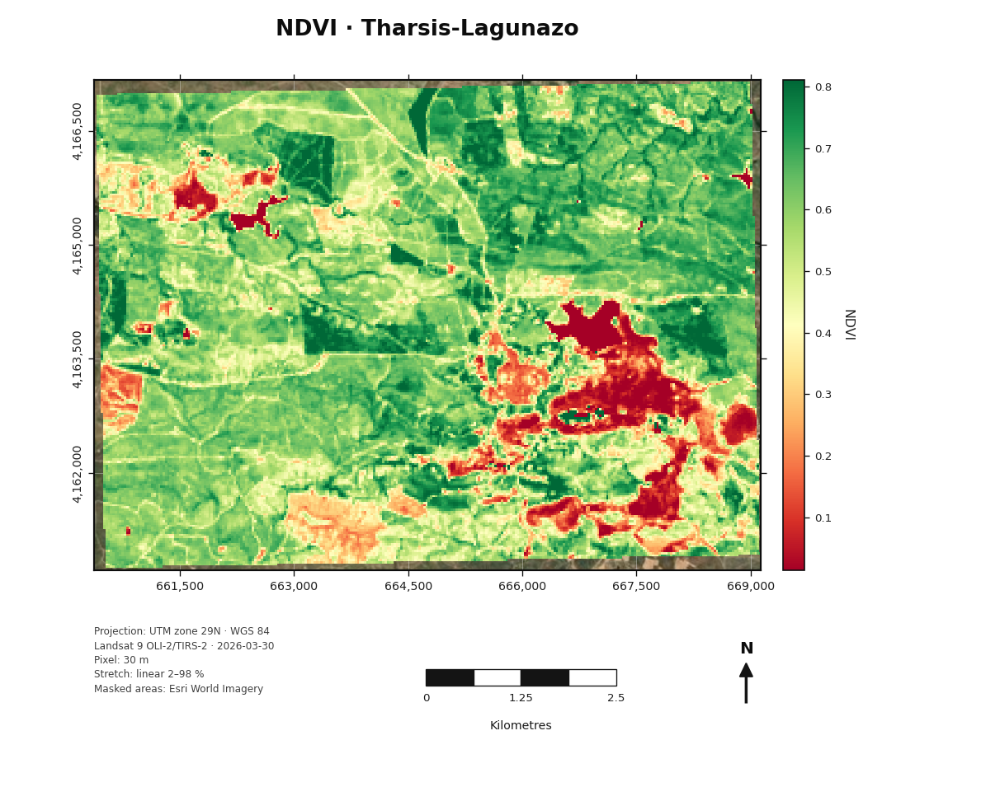

  saved  fig_00b_analysis_mask.png  +  fig_00b_analysis_mask.pdf   (400 dpi)


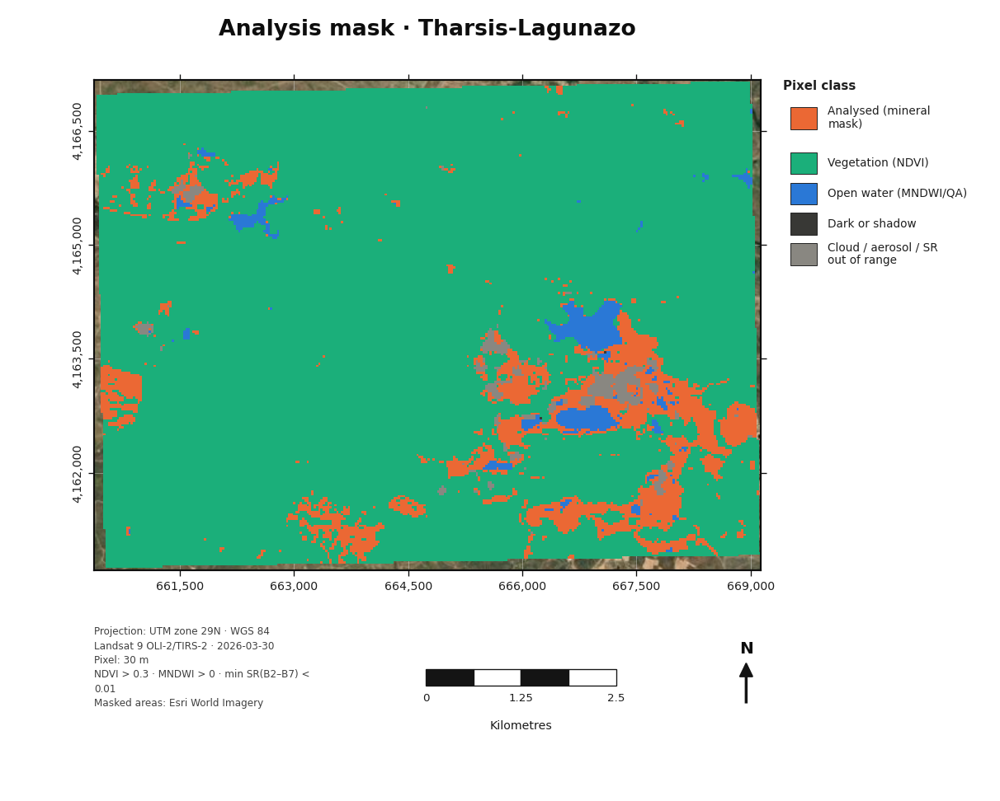

In [ ]:
with np.errstate(divide="ignore", invalid="ignore"):
    NDVI  = (R[5] - R[4]) / (R[5] + R[4])
    MNDWI = (R[3] - R[6]) / (R[3] + R[6])
NDVI[~INSIDE] = np.nan; MNDWI[~INSIDE] = np.nan

MIN_SR = np.full((H, W), np.nan, dtype="float32")
MIN_SR[INSIDE] = cube[1:7, INSIDE].min(axis=0)            # B2–B7

QA_BAD    = L["qa_bad"] | (L["high_aerosol"] if MASK_HIGH_AEROSOL else False)
OUT_RANGE = INSIDE & ~L["in_range"]
WATER     = INSIDE & ~QA_BAD & ((MNDWI > MNDWI_WATER_THRESHOLD) | L["qa_water"])
VEG       = INSIDE & (NDVI > NDVI_VEG_THRESHOLD)
DARK      = INSIDE & (MIN_SR < DARK_SR_MIN)

# exclusive class code (lowest priority first, then overwrite); -1 = outside AOI
MASK_CODE = np.full((H, W), -1, dtype=np.int16)
MASK_CODE[INSIDE] = 0 
MASK_CODE[DARK] = 3
MASK_CODE[VEG] = 1
MASK_CODE[OUT_RANGE] = 4
MASK_CODE[WATER] = 2
MASK_CODE[INSIDE & QA_BAD] = 4
MASK_NAMES  = ["Analysed (mineral mask)", "Vegetation (NDVI)", "Open water (MNDWI/QA)", "Dark or shadow",
               "Cloud / aerosol / SR out of range"]
MASK_COLORS = ["#eb6834", "#1baf7a", "#2a78d6", "#383835", "#898781"]

MASK_MIN = MASK_CODE == 0
if MASK_MIN.sum() < 100:
    raise RuntimeError(f"Only {int(MASK_MIN.sum())} pixels pass the mineral mask - check the AOI, the QA layers and the "
                       "NDVI / MNDWI / DARK_SR_MIN thresholds before continuing.")
BASE_NOVEG = INSIDE & ~QA_BAD & ~OUT_RANGE & ~WATER & ~DARK      # used by the NDVI sensitivity test

def mineral_layer(arr, mask=None):
    """Copy of a 2-D product with NaN outside the mineral mask."""
    out = np.array(arr, dtype="float32", copy=True)
    out[~(MASK_MIN if mask is None else mask)] = np.nan
    return out

mask_rows = []
n_in = int(INSIDE.sum())
for k, name in enumerate(MASK_NAMES):
    n = int((MASK_CODE == k).sum())
    mask_rows.append({"class": name, "pixels": n, "area_km2": round(n * PIXEL_AREA_KM2, 3),
                      "percent_of_AOI": round(100 * n / max(n_in, 1), 1)})
MASK_TABLE = pd.DataFrame(mask_rows)
MASK_TABLE.to_csv(TABLE_DIR / "tab_01_mask_summary.csv", index=False)
print(MASK_TABLE.to_string(index=False))
if MASK_MIN.sum() < 0.15 * n_in:
    print(f"\nNOTE: only {100*MASK_MIN.sum()/max(n_in,1):.1f} % of the AOI is analysed. Results are restricted to "
          "bare surfaces in this scene; compare with a late-summer scene before generalising.")
if not L["qa_path"]:
    print("NOTE: no QA_PIXEL file was used - check the natural-colour composite for clouds and shadows.")

fig = plot_single_band(NDVI, f"NDVI · {SITE_NAME}", "NDVI", cmap="RdYlGn", fname="fig_00_ndvi")
plt.show()
fig = plot_categorical(MASK_CODE, f"Analysis mask · {SITE_NAME}", MASK_COLORS, MASK_NAMES,
                       fname="fig_00b_analysis_mask", key_title="Pixel class",
                       extra=[f"NDVI > {NDVI_VEG_THRESHOLD:g} · MNDWI > {MNDWI_WATER_THRESHOLD:g} · "
                              f"min SR(B2-B7) < {DARK_SR_MIN:g}"])
plt.show()

### 4·b · Thermal context: land-surface temperature (TIRS band 10)

  saved  fig_14_lst_thermal_B10.png  +  fig_14_lst_thermal_B10.pdf   (400 dpi)


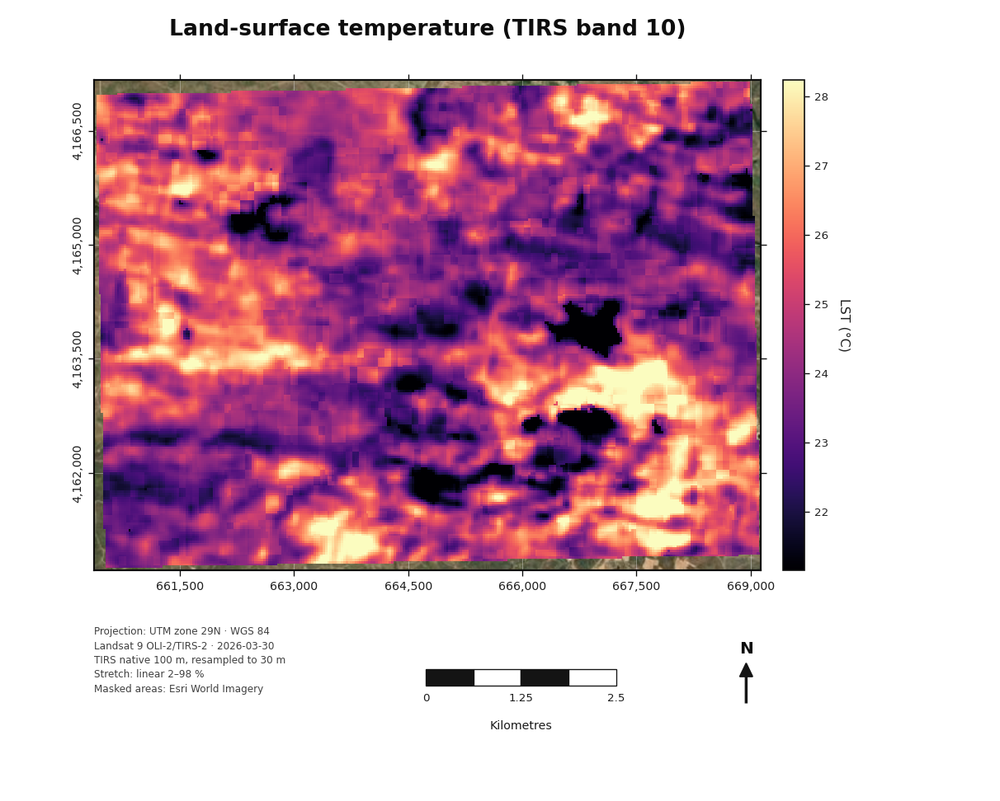

                            class  pixels  median_C  p10_C  p90_C
          Analysed (mineral mask)    5145     26.53  24.37  28.46
                Vegetation (NDVI)   52419     24.34  22.67  26.25
            Open water (MNDWI/QA)    1135     19.71  18.53  24.82
                   Dark or shadow       2     22.09  21.25  22.93
Cloud / aerosol / SR out of range     741     27.23  25.26  29.00


In [7]:
if LST is not None:
    fig = plot_single_band(LST, "Land-surface temperature (TIRS band 10)", "LST (°C)", cmap="magma",
                           fname="fig_14_lst_thermal_B10",
                           pixel_note="TIRS native 100 m, resampled to 30 m")
    plt.show()
    lst_rows = []
    for k, name in enumerate(MASK_NAMES):
        v = LST[(MASK_CODE == k) & np.isfinite(LST)]
        if v.size:
            lst_rows.append({"class": name, "pixels": v.size, "median_C": round(float(np.median(v)), 2),
                             "p10_C": round(float(np.percentile(v, 10)), 2), "p90_C": round(float(np.percentile(v, 90)), 2)})
    LST_TABLE = pd.DataFrame(lst_rows)
    LST_TABLE.to_csv(TABLE_DIR / "tab_02_lst_by_mask_class.csv", index=False)
    print(LST_TABLE.to_string(index=False))
else:
    print("B10 thermal band not provided - skipping LST.")

## 5 · Colour composites (context)

  saved  fig_01_natural_color.png  +  fig_01_natural_color.pdf   (400 dpi)


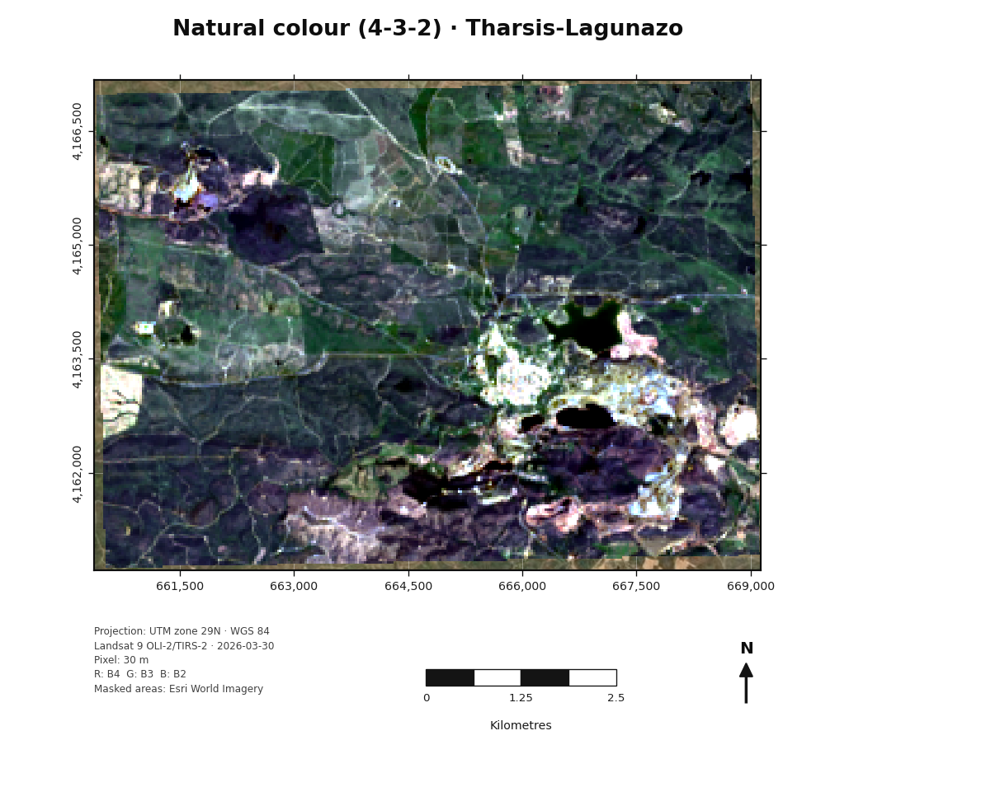

  saved  fig_02_falsecolor_753.png  +  fig_02_falsecolor_753.pdf   (400 dpi)


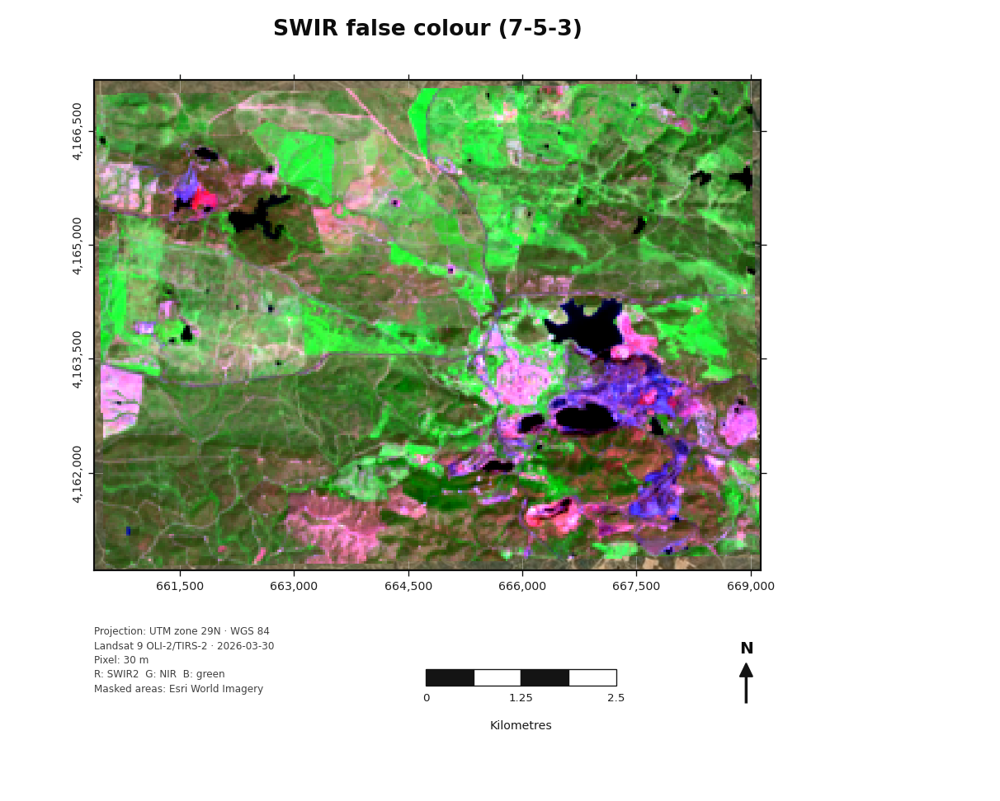

  saved  fig_03_falsecolor_652.png  +  fig_03_falsecolor_652.pdf   (400 dpi)


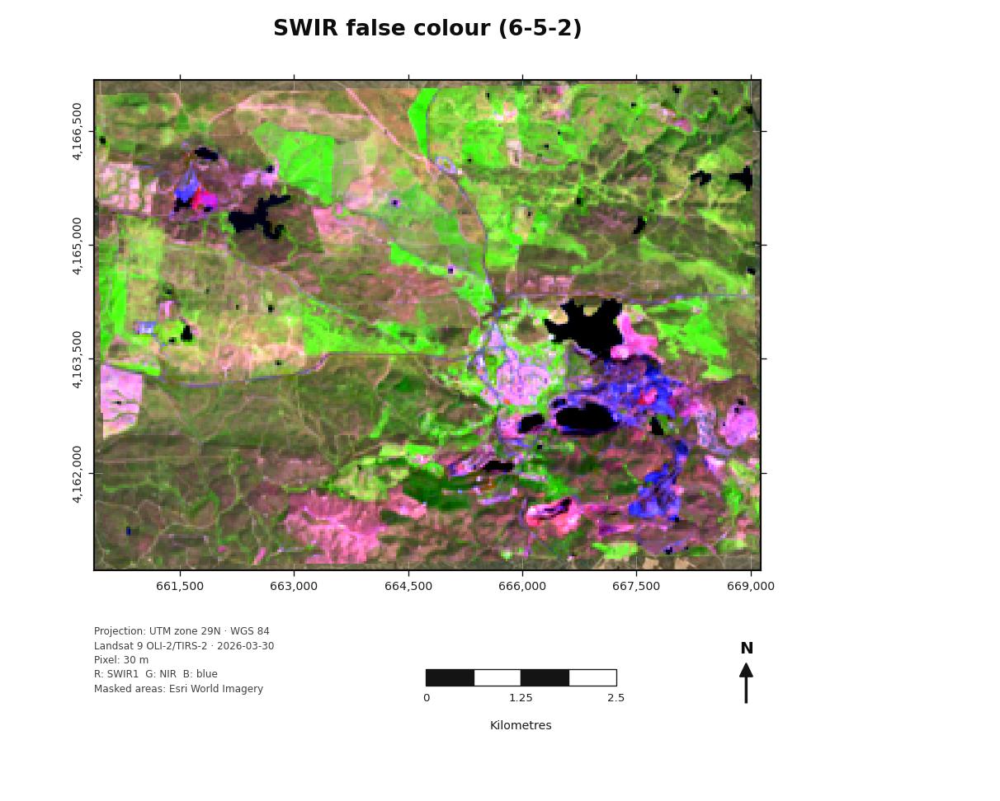

In [8]:
def _ctx(arr):
    out = arr.copy(); out[~INSIDE] = np.nan
    return out

fig = plot_rgb(make_rgb(_ctx(R[4]), _ctx(R[3]), _ctx(R[2])), f"Natural colour (4-3-2) · {SITE_NAME}",
               subtitle="R: B4  G: B3  B: B2", fname="fig_01_natural_color")
plt.show()
fig = plot_rgb(make_rgb(_ctx(R[7]), _ctx(R[5]), _ctx(R[3])), "SWIR false colour (7-5-3)",
               subtitle="R: SWIR2  G: NIR  B: green", fname="fig_02_falsecolor_753")
plt.show()
fig = plot_rgb(make_rgb(_ctx(R[6]), _ctx(R[5]), _ctx(R[2])), "SWIR false colour (6-5-2)",
               subtitle="R: SWIR1  G: NIR  B: blue", fname="fig_03_falsecolor_652")
plt.show()

## 6 · Spectral indices

Ratios suppress albedo and topographic shading (Sabins, 1999). For each index the table gives the formula, the physical basis,
other surfaces that raise it, and how it is labelled in the literature. High values flag the target.

| Index (key) | OLI formula | Physical basis | Also raised by | Literature label |
|---|---|---|---|---|
| Fe³⁺ charge transfer (`Fe3_B4B2`) | B4 / B2 | Fe³⁺ absorption in the blue (jarosite ~0.43 µm) | red soils, dry vegetation; aerosol errors in B2 | TM 3/1 "iron oxide" |
| Fe³⁺, blue-free check (`Fe3_B4B3`) | B4 / B3 | the same absorption edge, measured with green instead of blue | as above, without the B2 caveat | ASTER 2/1, Sentinel-2 4/3 "ferric iron" |
| NIR Fe³⁺ absorption depth (`FeCF_depthB5`) | 1 − B5 / [B4 + (B6 − B4)·(λ5 − λ4)/(λ6 − λ4)] | Fe³⁺ crystal-field band near 0.85–0.95 µm depresses B5 below the B4–B6 continuum | dark or wet surfaces with low NIR; strongly (inversely) tied to NDVI, because both depend on B5 against B4 | single-band depth; a coarse analogue of Fe-feature depth mapping |
| SWIR1 / NIR (`SWIR1_NIR_B6B5`) | B6 / B5 | low NIR relative to SWIR1: the Fe³⁺ 0.9 µm band and no NIR vegetation plateau | moisture, dark waste | "ferric oxides" (ASTER 4/3, Sentinel-2 11/8), but "ferrous minerals" (TM 5/4) in the TM mineral-composite convention |
| Gossan (`Gossan_B6B4`) | B6 / B4 | bright SWIR1 against the red band | bare soils | ASTER 4/2, Sentinel-2 11/4 "gossan" |
| OH/SO₄ ± NPV (`OH_SO4_B6B7`) | B6 / B7 | absorptions inside B7 (2.11–2.29 µm): Al-OH clays and micas, alunite, jarosite (metal-OH), gypsum | dry plant material (lignocellulose absorptions near 2.1 and 2.3 µm); green vegetation, because leaf water absorbs more strongly near 2.2 µm than near 1.6 µm, so partly vegetated edge pixels read high | TM 5/7 "clay / hydroxyl" |

In [ ]:
def safe_ratio(num, den, min_den=DARK_SR_MIN):
    """num/den with NaN where the denominator is below min_den or the result is not finite."""
    with np.errstate(divide="ignore", invalid="ignore"):
        r = num / den
        r[~np.isfinite(r) | ~(den >= min_den)] = np.nan
    return r

_w4, _w5, _w6 = OLI_WL[4], OLI_WL[5], OLI_WL[6]
with np.errstate(divide="ignore", invalid="ignore"):
    _cont5 = R[4] + (R[6] - R[4]) * (_w5 - _w4) / (_w6 - _w4)
    _depth5 = 1.0 - R[5] / _cont5
_depth5[~np.isfinite(_depth5)] = np.nan


# RAW_IDX
RAW_IDX = {
    "Fe3_B4B2":       safe_ratio(R[4], R[2]),
    "Fe3_B4B3":       safe_ratio(R[4], R[3]),
    "FeCF_depthB5":   _depth5,
    "SWIR1_NIR_B6B5": safe_ratio(R[6], R[5]),
    "Gossan_B6B4":    safe_ratio(R[6], R[4]),
    "OH_SO4_B6B7":    safe_ratio(R[6], R[7]),
}
IDX = {k: mineral_layer(v) for k, v in RAW_IDX.items()}
IDX_LABEL = {
    "Fe3_B4B2": "Fe³⁺ B4/B2", "Fe3_B4B3": "Fe³⁺ B4/B3 (blue-free)", "FeCF_depthB5": "NIR Fe³⁺ depth (B5)",
    "SWIR1_NIR_B6B5": "SWIR1/NIR B6/B5", "Gossan_B6B4": "Gossan B6/B4", "OH_SO4_B6B7": "OH/SO₄ ± NPV B6/B7",
}


R_FEOX, R_FERROUS, R_CLAY = IDX["Fe3_B4B2"], IDX["SWIR1_NIR_B6B5"], IDX["OH_SO4_B6B7"]

def describe(arr):
    v = arr[np.isfinite(arr)]
    if v.size == 0:
        return {"pixels": 0}
    p = np.percentile(v, [2, 25, 50, 75, 98])
    return {"pixels": int(v.size), "min": v.min(), "p2": p[0], "q1": p[1], "median": p[2], "q3": p[3],
            "p98": p[4], "max": v.max(), "mean": v.mean(), "sd": v.std()}

INDEX_TABLE = pd.DataFrame([{"index": IDX_LABEL[k], **describe(a)} for k, a in IDX.items()])
INDEX_TABLE.to_csv(TABLE_DIR / "tab_03_index_statistics.csv", index=False, float_format="%.4f")
print(INDEX_TABLE.round(3).to_string(index=False))

                 index  pixels    min     p2     q1  median     q3   p98   max   mean    sd
            Fe³⁺ B4/B2    5145  1.116  1.443  1.999   2.188  2.350 2.763 3.777  2.163 0.301
Fe³⁺ B4/B3 (blue-free)    5145  0.766  1.092  1.244   1.334  1.406 1.610 2.213  1.331 0.127
   NIR Fe³⁺ depth (B5)    5145 -0.725 -0.505 -0.320  -0.186 -0.029 0.164 0.319 -0.178 0.180
       SWIR1/NIR B6/B5    5145  0.646  0.948  1.161   1.290  1.466 2.130 3.496  1.345 0.287
          Gossan B6/B4    5145  0.864  1.035  1.593   1.854  2.159 2.814 3.971  1.882 0.449
    OH/SO₄ ± NPV B6/B7    5145  1.022  1.109  1.264   1.327  1.392 1.519 1.952  1.326 0.100


  saved  fig_04_ratio_ferric_B4B2.png  +  fig_04_ratio_ferric_B4B2.pdf   (400 dpi)


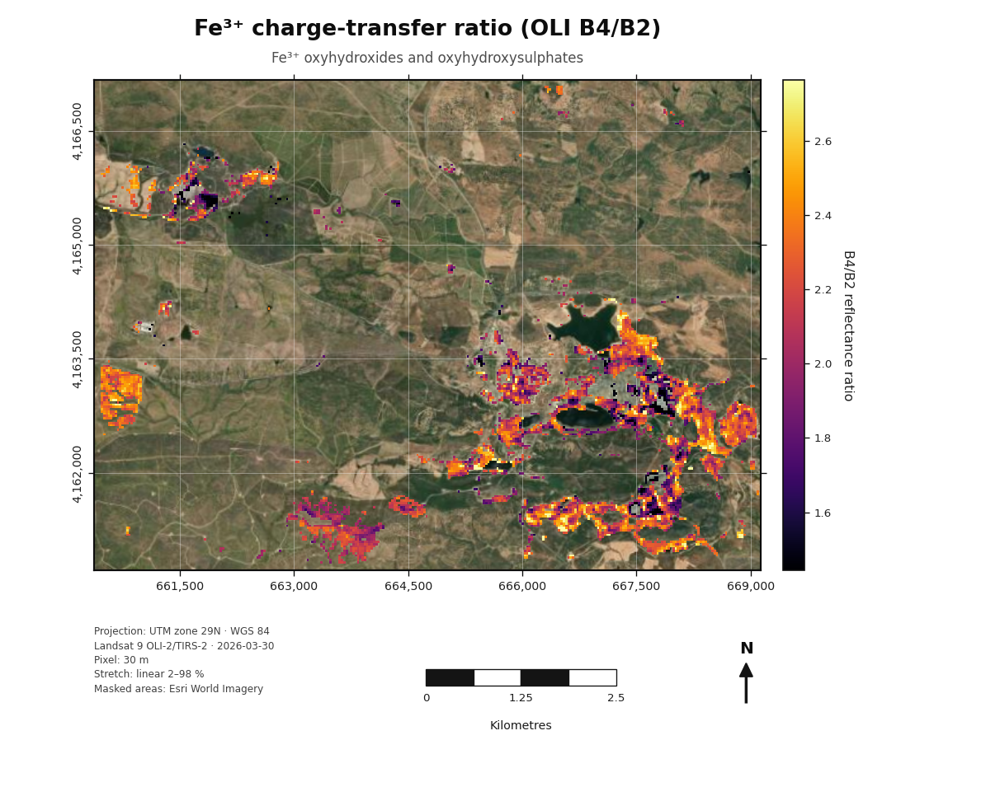

  saved  fig_05_ratio_swir1_nir_B6B5.png  +  fig_05_ratio_swir1_nir_B6B5.pdf   (400 dpi)


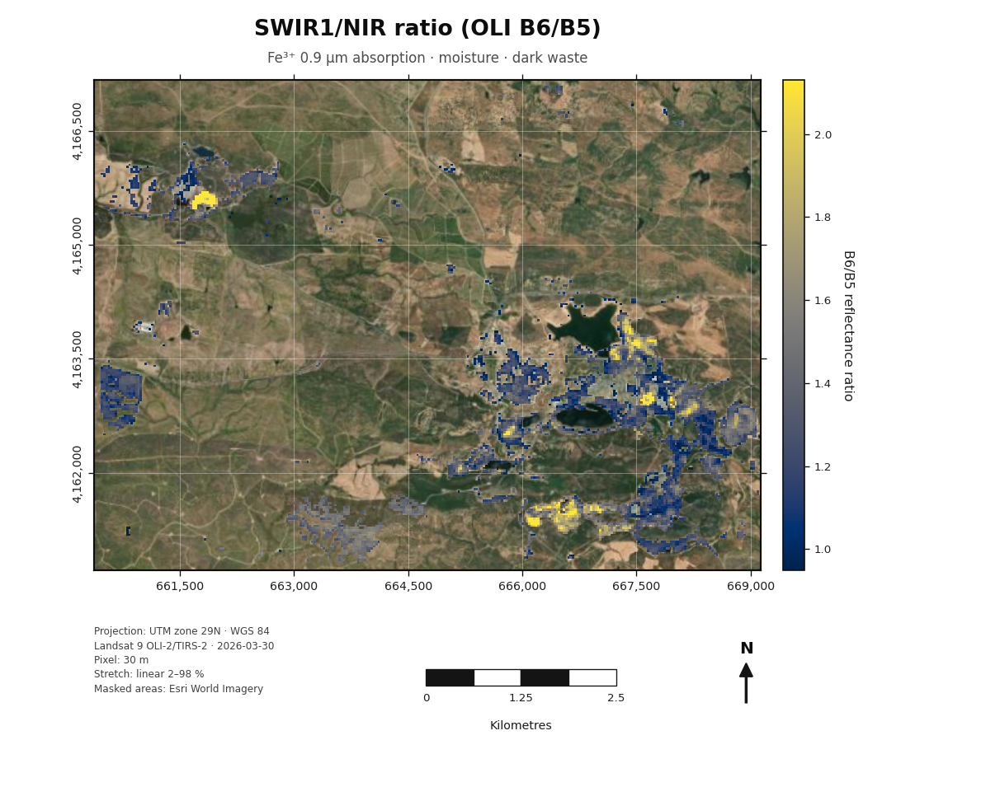

  saved  fig_06_ratio_OH_SO4_B6B7.png  +  fig_06_ratio_OH_SO4_B6B7.pdf   (400 dpi)


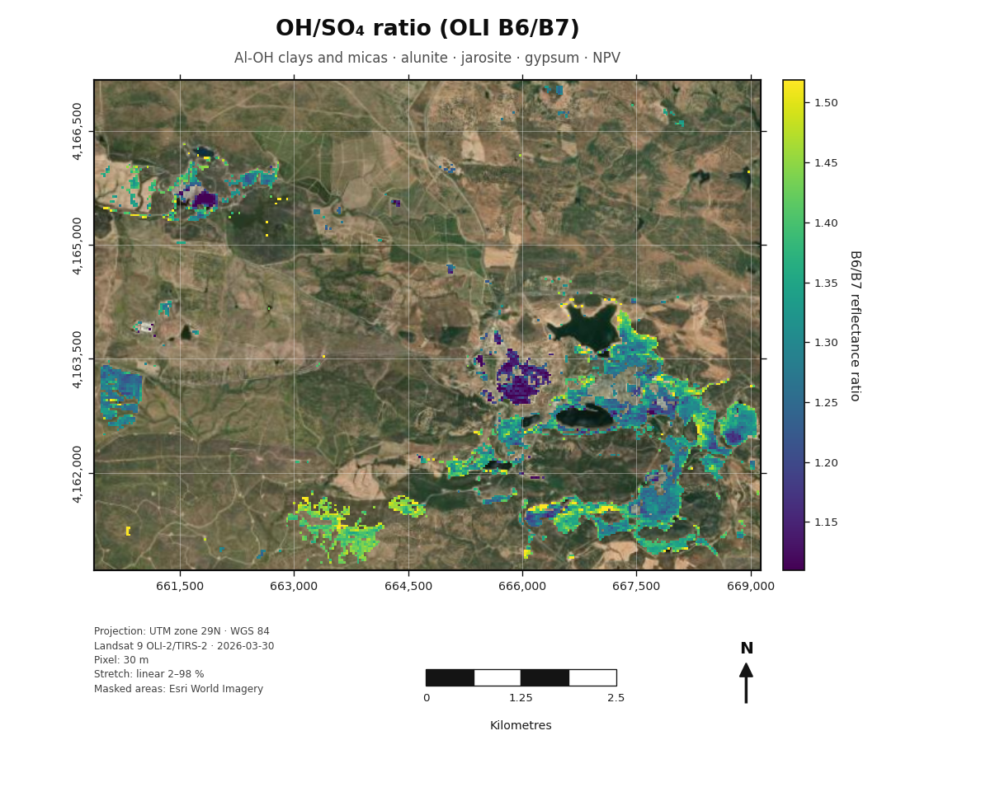

  saved  fig_04b_supplementary_fe_indices.png  +  fig_04b_supplementary_fe_indices.pdf   (400 dpi)


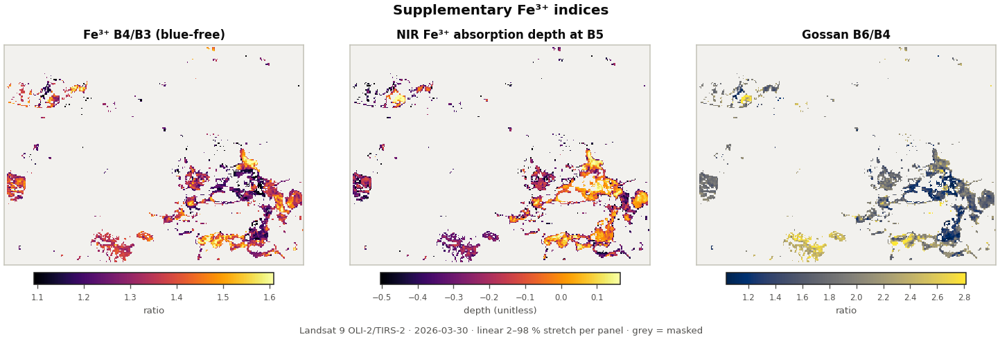

In [10]:
fig = plot_single_band(IDX["Fe3_B4B2"], "Fe³⁺ charge-transfer ratio (OLI B4/B2)\nFe³⁺ oxyhydroxides and oxyhydroxysulphates",
                       "B4/B2 reflectance ratio", cmap="inferno", fname="fig_04_ratio_ferric_B4B2")
plt.show()
fig = plot_single_band(IDX["SWIR1_NIR_B6B5"], "SWIR1/NIR ratio (OLI B6/B5)\nFe³⁺ 0.9 µm absorption · moisture · dark waste",
                       "B6/B5 reflectance ratio", cmap="cividis", fname="fig_05_ratio_swir1_nir_B6B5")
plt.show()
fig = plot_single_band(IDX["OH_SO4_B6B7"], "OH/SO₄ ratio (OLI B6/B7)\nAl-OH clays and micas · alunite · jarosite · gypsum · NPV",
                       "B6/B7 reflectance ratio", cmap="viridis", fname="fig_06_ratio_OH_SO4_B6B7")
plt.show()
fig = panel_maps([IDX["Fe3_B4B3"], IDX["FeCF_depthB5"], IDX["Gossan_B6B4"]],
                 ["Fe³⁺ B4/B3 (blue-free)", "NIR Fe³⁺ absorption depth at B5", "Gossan B6/B4"],
                 ["inferno", "inferno", "cividis"], "Supplementary Fe³⁺ indices",
                 fname="fig_04b_supplementary_fe_indices", cbar_labels=["ratio", "depth (unitless)", "ratio"])
plt.show()

## 7 · Ratio-RGB composite

**R = Fe³⁺ (B4/B2), G = OH/SO₄ (B6/B7), B = SWIR1/NIR (B6/B5)**, each stretched 2–98 % over the mineral mask.
Red–magenta = Fe³⁺-dominant, green = OH/SO₄-dominant, yellow = both. Colours are relative *within this mask*, not
absolute mineral classes. Masked pixels are transparent, so the basemap or background shows through.

  saved  fig_07_ratio_rgb.png  +  fig_07_ratio_rgb.pdf   (400 dpi)


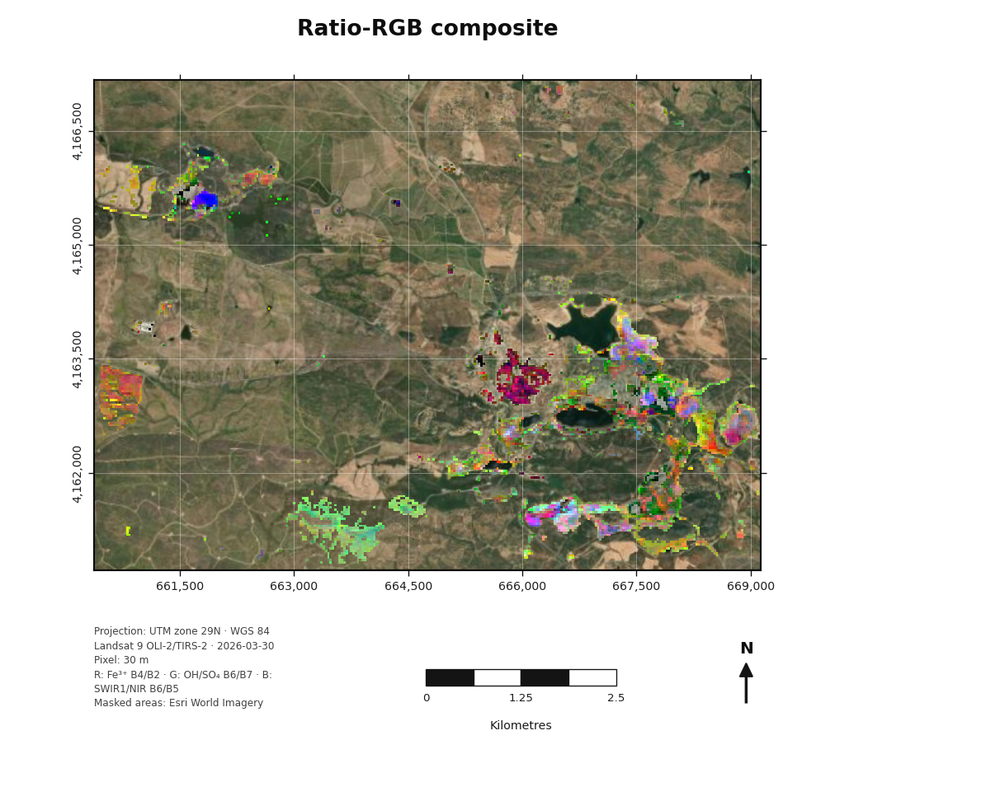

In [11]:
comp = make_rgb(IDX["Fe3_B4B2"], IDX["OH_SO4_B6B7"], IDX["SWIR1_NIR_B6B5"])
comp[~MASK_MIN] = np.nan
fig = plot_rgb(comp, "Ratio-RGB composite", subtitle="R: Fe³⁺ B4/B2 · G: OH/SO₄ B6/B7 · B: SWIR1/NIR B6/B5",
               fname="fig_07_ratio_rgb")
plt.show()

## 8 · Crósta technique: feature-oriented principal-component selection

PCA is run on a four-band subset over the mineral mask. The component whose **two diagnostic loadings have opposite
signs and are both strong** is selected, then oriented so the target is bright (Crósta & Moore, 1989;
Loughlin, 1991).

* **Iron oxides**: OLI 2-4-5-6 (TM 1-3-4-5); diagnostic pair B2/B4; oriented by B4 > 0.
* **Hydroxyls**: OLI 2-5-6-7 (TM 1-4-5-7); diagnostic pair B6/B7; oriented by B6 > 0.
* **Blue-free iron-oxide check**: OLI 3-4-5-6; pair B3/B4. Both standard subsets use B2 (see the USGS caveat in §6).

In [12]:
def crosta_fpcs(band_nums, diag_pair, ref_band, label, standardise=None, force_pc=None, verbose=True):
    standardise = CROSTA_STANDARDISE if standardise is None else standardise
    flat = np.stack([R[b][MASK_MIN] for b in band_nums], axis=-1).astype("float64")
    X = StandardScaler().fit_transform(flat) if standardise else flat - flat.mean(axis=0)
    pca = PCA().fit(X)
    comps, scores, var = pca.components_, pca.transform(X), pca.explained_variance_ratio_
    i1, i2, iref = band_nums.index(diag_pair[0]), band_nums.index(diag_pair[1]), band_nums.index(ref_band)
    cand = []
    for pc in range(1, len(band_nums)):                       # PC1 = albedo, excluded
        l1, l2 = comps[pc, i1], comps[pc, i2]
        if l1 * l2 < 0:
            cand.append((abs(l1 * l2), abs(l1) + abs(l2), pc))     # both loadings must carry weight
    if force_pc:
        best, rule = int(force_pc) - 1, "forced in CONFIG"
    elif cand:
        best, rule = max(cand)[2], "automatic"
    else:
        best, rule = len(band_nums) - 1, "fallback: no opposite-sign component"
    sc = scores[:, best].copy()
    flipped = comps[best, iref] < 0
    if flipped:
        sc = -sc
    img = np.full((H, W), np.nan, dtype="float32"); img[MASK_MIN] = sc
    load = comps[best] * (-1 if flipped else 1)
    strength = min(abs(load[i1]), abs(load[i2]))
    if verbose:
        print(f"\n=== Crósta FPCS: {label} | OLI bands {band_nums} | "
              f"{'correlation' if standardise else 'covariance'} matrix ===")
        hdr = "PC   " + "".join(f"    B{b}" for b in band_nums) + "   %var"
        print(hdr); print("-" * len(hdr))
        for pc in range(len(band_nums)):
            row = "".join(f" {comps[pc, j]:+5.2f}" for j in range(len(band_nums)))
            print(f"PC{pc+1} {row}  {100*var[pc]:5.1f}" + ("   <== selected" if pc == best else ""))
        print(f"Selected PC{best+1} ({rule}); oriented so B{ref_band} is positive"
              f"{' (sign flipped)' if flipped else ''}; diagnostic strength min|l| = {strength:.2f}")
        if strength < 0.25:
            print("  WARNING: weak diagnostic loadings - check whether another component isolates the target.")
        if var[best] < 0.01:
            print(f"  NOTE: PC{best+1} explains {100*var[best]:.2f} % of the variance - inspect the map for noise.")
    return {"image": img, "pc": best, "loadings": load, "var": var[best], "rule": rule, "strength": strength,
            "standardised": standardise}

def spearman_layers(a, b, mask=None, max_n=50000, seed=0):
    m = np.isfinite(a) & np.isfinite(b)
    if mask is not None:
        m &= mask
    idx = np.flatnonzero(m)
    if idx.size > max_n:
        idx = np.random.default_rng(seed).choice(idx, max_n, replace=False)
    if idx.size < 10:
        return np.nan, int(idx.size)
    return float(stats.spearmanr(a.ravel()[idx], b.ravel()[idx])[0]), int(idx.size)

CR_FE  = crosta_fpcs([2, 4, 5, 6], (2, 4), 4, "iron oxides", force_pc=CROSTA_FE_PC)
CR_OH  = crosta_fpcs([2, 5, 6, 7], (6, 7), 6, "hydroxyls", force_pc=CROSTA_OH_PC)
CR_FE3 = crosta_fpcs([3, 4, 5, 6], (3, 4), 4, "iron oxides, blue-free check")
CR_FEOX, CR_OHIMG = CR_FE["image"], CR_OH["image"]

CROSTA_TABLE = pd.DataFrame([
    {"component": "Crósta Fe (2-4-5-6)", "selected_PC": CR_FE["pc"] + 1, "variance_pct": 100 * CR_FE["var"],
     "min_diag_loading": CR_FE["strength"], "spearman_vs": "B4/B2",
     "rho": spearman_layers(CR_FE["image"], IDX["Fe3_B4B2"])[0]},
    {"component": "Crósta Fe blue-free (3-4-5-6)", "selected_PC": CR_FE3["pc"] + 1, "variance_pct": 100 * CR_FE3["var"],
     "min_diag_loading": CR_FE3["strength"], "spearman_vs": "B4/B3",
     "rho": spearman_layers(CR_FE3["image"], IDX["Fe3_B4B3"])[0]},
    {"component": "Crósta OH (2-5-6-7)", "selected_PC": CR_OH["pc"] + 1, "variance_pct": 100 * CR_OH["var"],
     "min_diag_loading": CR_OH["strength"], "spearman_vs": "B6/B7",
     "rho": spearman_layers(CR_OH["image"], IDX["OH_SO4_B6B7"])[0]},
])
CROSTA_TABLE.to_csv(TABLE_DIR / "tab_04_crosta_selection.csv", index=False, float_format="%.3f")
print("\n" + CROSTA_TABLE.round(3).to_string(index=False))
for _, r_ in CROSTA_TABLE.iterrows():
    if np.isfinite(r_["rho"]) and r_["rho"] < 0.5:
        print(f"  CHECK: {r_['component']} correlates weakly with {r_['spearman_vs']} (rho = {r_['rho']:.2f}).")


=== Crósta FPCS: iron oxides | OLI bands [2, 4, 5, 6] | correlation matrix ===
PC       B2    B4    B5    B6   %var
------------------------------------
PC1  +0.47 +0.54 +0.51 +0.48   76.7
PC2  +0.68 +0.26 -0.36 -0.58   16.1
PC3  -0.07 -0.13 +0.78 -0.61    4.9
PC4  -0.56 +0.79 -0.11 -0.23    2.3   <== selected
Selected PC4 (automatic); oriented so B4 is positive; diagnostic strength min|l| = 0.56

=== Crósta FPCS: hydroxyls | OLI bands [2, 5, 6, 7] | correlation matrix ===
PC       B2    B5    B6    B7   %var
------------------------------------
PC1  +0.39 +0.52 +0.53 +0.54   76.9
PC2  +0.89 -0.01 -0.37 -0.27   16.2
PC3  -0.22 +0.85 -0.29 -0.38    6.1
PC4  +0.08 -0.05 +0.71 -0.70    0.8   <== selected
Selected PC4 (automatic); oriented so B6 is positive; diagnostic strength min|l| = 0.70
  NOTE: PC4 explains 0.80 % of the variance - inspect the map for noise.

=== Crósta FPCS: iron oxides, blue-free check | OLI bands [3, 4, 5, 6] | correlation matrix ===
PC       B3    B4    B5    B6 

  saved  fig_08_crosta_iron_oxide.png  +  fig_08_crosta_iron_oxide.pdf   (400 dpi)


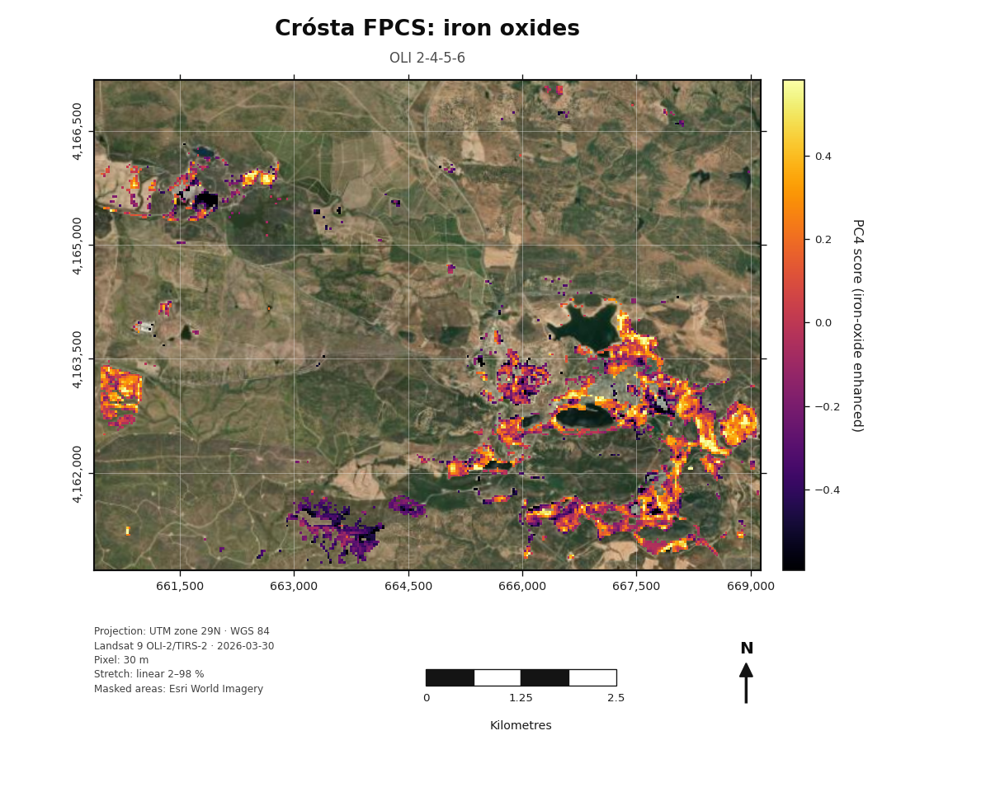

  saved  fig_09_crosta_hydroxyl.png  +  fig_09_crosta_hydroxyl.pdf   (400 dpi)


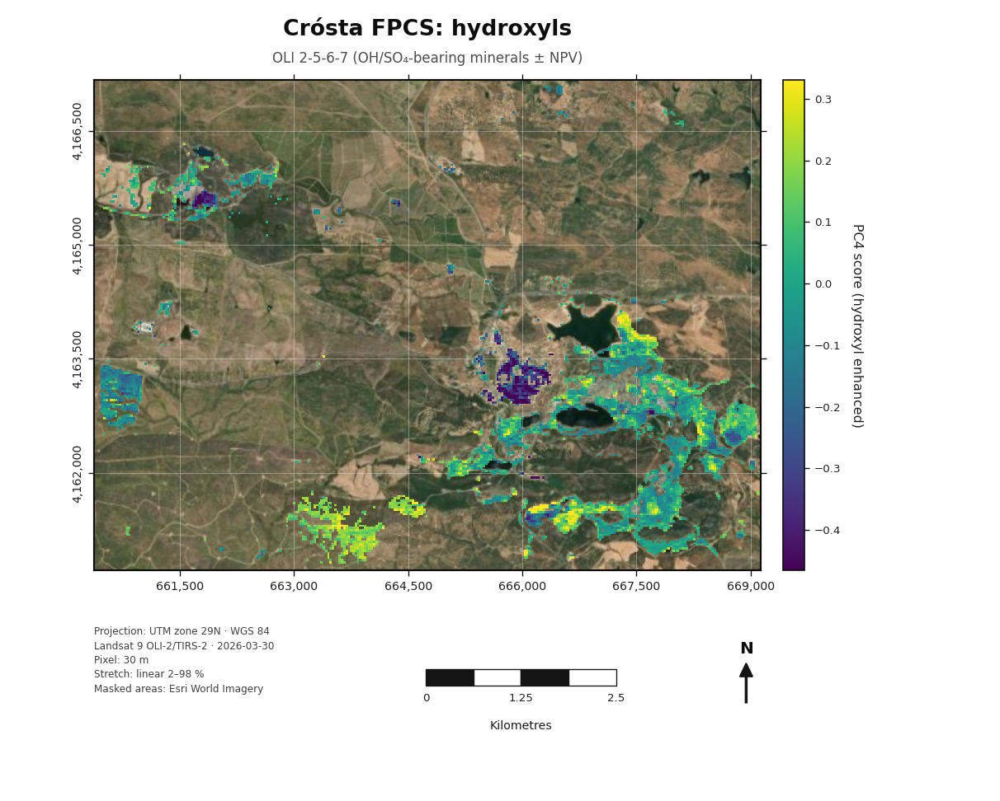

In [13]:
fig = plot_single_band(CR_FE["image"], "Crósta FPCS: iron oxides\nOLI 2-4-5-6",
                       f"PC{CR_FE['pc']+1} score (iron-oxide enhanced)", cmap="inferno",
                       fname="fig_08_crosta_iron_oxide")
plt.show()
fig = plot_single_band(CR_OH["image"], "Crósta FPCS: hydroxyls\nOLI 2-5-6-7 (OH/SO₄-bearing minerals ± NPV)",
                       f"PC{CR_OH['pc']+1} score (hydroxyl enhanced)", cmap="viridis",
                       fname="fig_09_crosta_hydroxyl")
plt.show()

## 9 · Decorrelation stretch (SWIR 7-6-5)

The SWIR bands are strongly correlated, so a plain 7-6-5 composite looks dull. Whitening the band covariance
(Gillespie et al., 1986) exaggerates colour differences while keeping the hue relationships, which makes subtle
variation across the mine waste visible. It is computed over the mineral mask only.

  saved  fig_10_decorrelation_stretch_765.png  +  fig_10_decorrelation_stretch_765.pdf   (400 dpi)


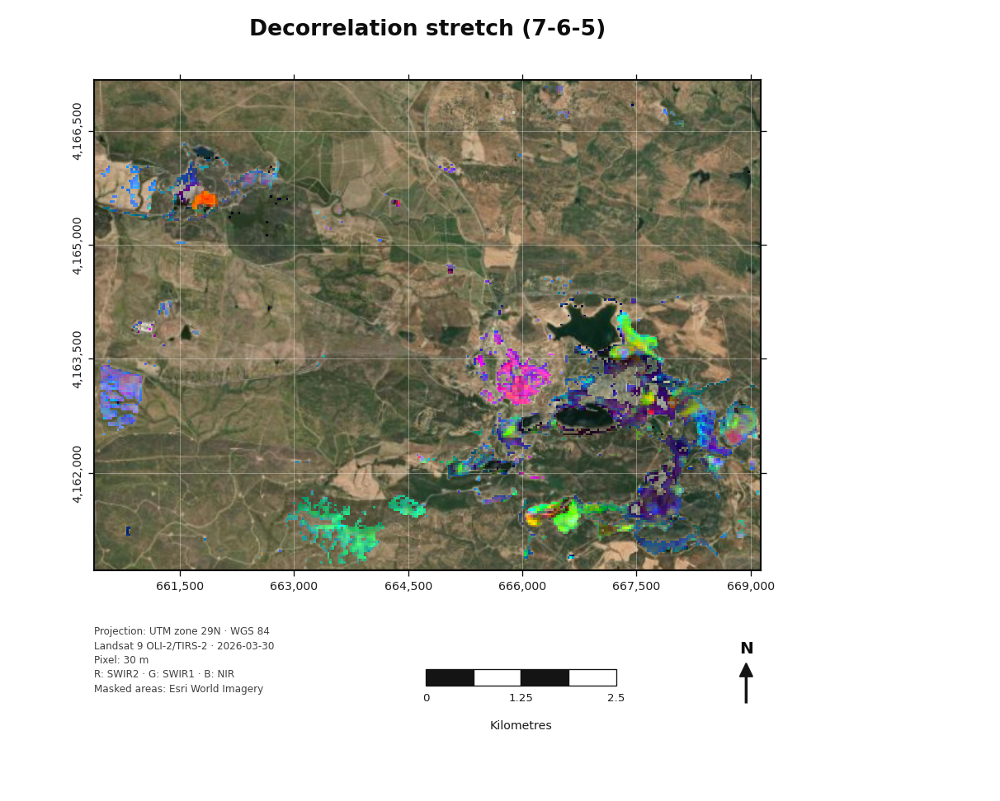

In [14]:
def decorr_stretch(band_nums, lo=2, hi=98):
    flat = np.stack([R[b][MASK_MIN] for b in band_nums], axis=-1).astype("float64")
    mean, cov = flat.mean(axis=0), np.cov(flat, rowvar=False)
    eval_, evec = np.linalg.eigh(cov)
    eval_ = np.clip(eval_, 1e-12, None)
    W_whiten = evec @ np.diag(1.0 / np.sqrt(eval_)) @ evec.T
    out_flat = (flat - mean) @ W_whiten
    out = np.full((H, W, 3), np.nan, dtype="float32")
    for c in range(3):
        ch = np.full((H, W), np.nan, dtype="float32"); ch[MASK_MIN] = out_flat[:, c]
        out[..., c] = pct_stretch(ch, lo, hi)
    return out

dcs = decorr_stretch([7, 6, 5])
fig = plot_rgb(dcs, "Decorrelation stretch (7-6-5)", subtitle="R: SWIR2 · G: SWIR1 · B: NIR",
               fname="fig_10_decorrelation_stretch_765")
plt.show()

## 10 · Anomaly thresholds and the Fe³⁺ / OH–SO₄ overlap map

Continuous maps are turned into anomaly classes with two independent thresholding methods:

* **Mean + kσ** of each index over the mineral mask (k = `SIGMA_LEVELS`).
* **Concentration–area (C–A) fractal model** (Cheng et al., 1994): log(area with index ≥ v) against log(v) is
  fitted with three straight segments. The two breakpoints separate background, a weak-anomaly population and a
  strong-anomaly population. It applies to the positive ratio indices only.

A pixel counts as a **consensus anomaly** when both the band ratio *and* the Crósta component exceed their mean +
kσ for the first value in `SIGMA_LEVELS` (the last value gives the strict version). The Fe³⁺ and OH/SO₄ consensus anomalies are then combined into four classes. Pixels anomalous in both are the
most jarosite- or gossan-like candidates at Landsat resolution, **pending field and XRD/FTIR confirmation**.

      layer   method  threshold  pixels  area_km2  percent_of_analysed
   Fe3_B4B2 mean+1sd      2.464     666     0.599               12.945
   Fe3_B4B2 mean+2sd      2.765     103     0.093                2.002
   Fe3_B4B2   CA_low      2.023    3725     3.352               72.400
   Fe3_B4B2  CA_high      2.312    1575     1.418               30.612
OH_SO4_B6B7 mean+1sd      1.426     762     0.686               14.810
OH_SO4_B6B7 mean+2sd      1.525      91     0.082                1.769
OH_SO4_B6B7   CA_low      1.262    3897     3.507               75.743
OH_SO4_B6B7  CA_high      1.383    1446     1.301               28.105
  Crosta_Fe mean+1sd      0.300     805     0.724               15.646
  Crosta_Fe mean+2sd      0.601      87     0.078                1.691
  Crosta_OH mean+1sd      0.179     699     0.629               13.586
  Crosta_OH mean+2sd      0.358      76     0.068                1.477
  saved  fig_15_ca_fractal_thresholds.png  +  fig_15_ca_fractal_thresholds.pd

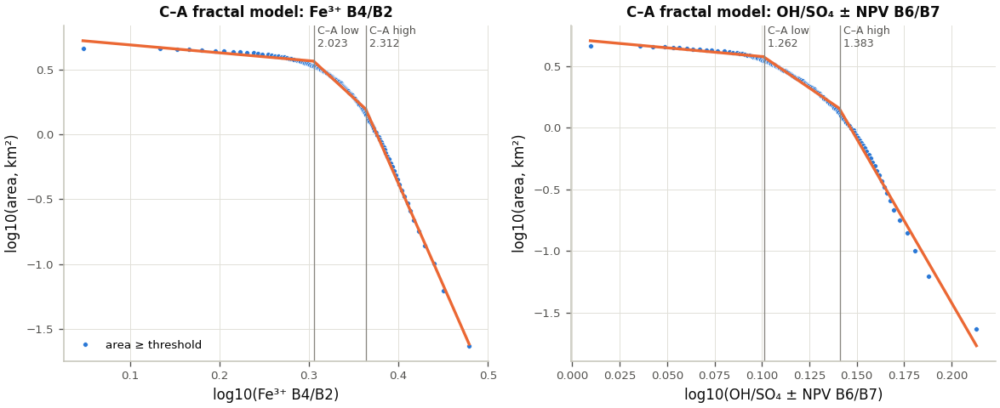

In [ ]:
def sigma_thresholds(arr, levels=SIGMA_LEVELS):
    v = arr[np.isfinite(arr)]
    mu, sd = float(v.mean()), float(v.std())
    return {f"mean+{k:g}sd": mu + k * sd for k in levels}

def ca_fractal(arr, n=CA_N_THRESHOLDS, min_pts=8):
    """Three-segment piecewise-linear fit of log10(area >= v) vs log10(v). Returns (t_low, t_high, curve)."""
    v = arr[np.isfinite(arr) & (arr > 0)]
    thr = np.unique(np.quantile(v, np.linspace(0.0, 0.995, n)))
    area = np.array([(v >= t).sum() for t in thr]) * PIXEL_AREA_KM2
    x, y = np.log10(thr), np.log10(area)
    m = len(x)
    if m < 3 * min_pts:
        return np.nan, np.nan, (x, y, None)
    def sse(s, e):
        p = np.polyfit(x[s:e], y[s:e], 1)
        return float(((np.polyval(p, x[s:e]) - y[s:e]) ** 2).sum())
    best = None
    for i in range(min_pts, m - 2 * min_pts + 1):
        left = sse(0, i)
        for j in range(i + min_pts, m - min_pts + 1):
            tot = left + sse(i, j) + sse(j, m)
            if best is None or tot < best[0]:
                best = (tot, i, j)
    _, i, j = best
    return float(thr[i]), float(thr[j]), (x, y, (i, j))

THR = {}
for key, arr in [("Fe3_B4B2", IDX["Fe3_B4B2"]), ("OH_SO4_B6B7", IDX["OH_SO4_B6B7"]),
                 ("Crosta_Fe", CR_FE["image"]), ("Crosta_OH", CR_OH["image"])]:
    THR[key] = sigma_thresholds(arr)
CA = {}
for key in ("Fe3_B4B2", "OH_SO4_B6B7"):
    t_lo, t_hi, curve = ca_fractal(IDX[key])
    CA[key] = {"CA_low": t_lo, "CA_high": t_hi, "curve": curve}
    THR[key].update({"CA_low": t_lo, "CA_high": t_hi})

thr_rows = []
for key, d in THR.items():
    arr = {"Fe3_B4B2": IDX["Fe3_B4B2"], "OH_SO4_B6B7": IDX["OH_SO4_B6B7"],
           "Crosta_Fe": CR_FE["image"], "Crosta_OH": CR_OH["image"]}[key]
    for method, t in d.items():
        n = int((arr >= t).sum()) if np.isfinite(t) else 0
        thr_rows.append({"layer": key, "method": method, "threshold": t, "pixels": n,
                         "area_km2": n * PIXEL_AREA_KM2, "percent_of_analysed": 100 * n / max(MASK_MIN.sum(), 1)})
THRESHOLD_TABLE = pd.DataFrame(thr_rows)
THRESHOLD_TABLE.to_csv(TABLE_DIR / "tab_05_anomaly_thresholds.csv", index=False, float_format="%.4f")
print(THRESHOLD_TABLE.round(3).to_string(index=False))

# C-A plots
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, key in zip(axes, ("Fe3_B4B2", "OH_SO4_B6B7")):
    x, y, br = CA[key]["curve"]
    ax.plot(x, y, "o", ms=3.5, color=SERIES[0], mec="white", mew=0.4, label="area ≥ threshold")
    if br is not None:
        i, j = br
        for s, e in [(0, i), (i, j), (j, len(x))]:
            p = np.polyfit(x[s:e], y[s:e], 1)
            ax.plot(x[s:e], np.polyval(p, x[s:e]), "-", lw=2, color=SERIES[1])
        for t, name in [(CA[key]["CA_low"], "C-A low"), (CA[key]["CA_high"], "C-A high")]:
            ax.axvline(np.log10(t), color=MUTED, lw=0.8)
            ax.text(np.log10(t), ax.get_ylim()[1], f" {name}\n {t:.3f}", va="top", ha="left", fontsize=7.5,
                    color=INK_2)
    ax.set_xlabel(f"log10({IDX_LABEL[key]})"); ax.set_ylabel("log10(area, km²)")
    ax.set_title(f"C-A fractal model: {IDX_LABEL[key]}", fontsize=10)
    style_chart(ax, grid_axis="both")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
save_fig(fig, "fig_15_ca_fractal_thresholds")
plt.show()

                                   class  pixels  area_km2  percent_of_analysed
                   Background (analysed)    4332     3.899                 84.2
                       Fe³⁺ anomaly only     363     0.327                  7.1
                     OH/SO₄ anomaly only     422     0.380                  8.2
                   Fe³⁺ + OH/SO₄ anomaly      28     0.025                  0.5
Fe³⁺ + OH/SO₄ anomaly (strict, mean+2sd)       1     0.001                  0.0
  saved  fig_16_consensus_anomaly_overlap.png  +  fig_16_consensus_anomaly_overlap.pdf   (400 dpi)


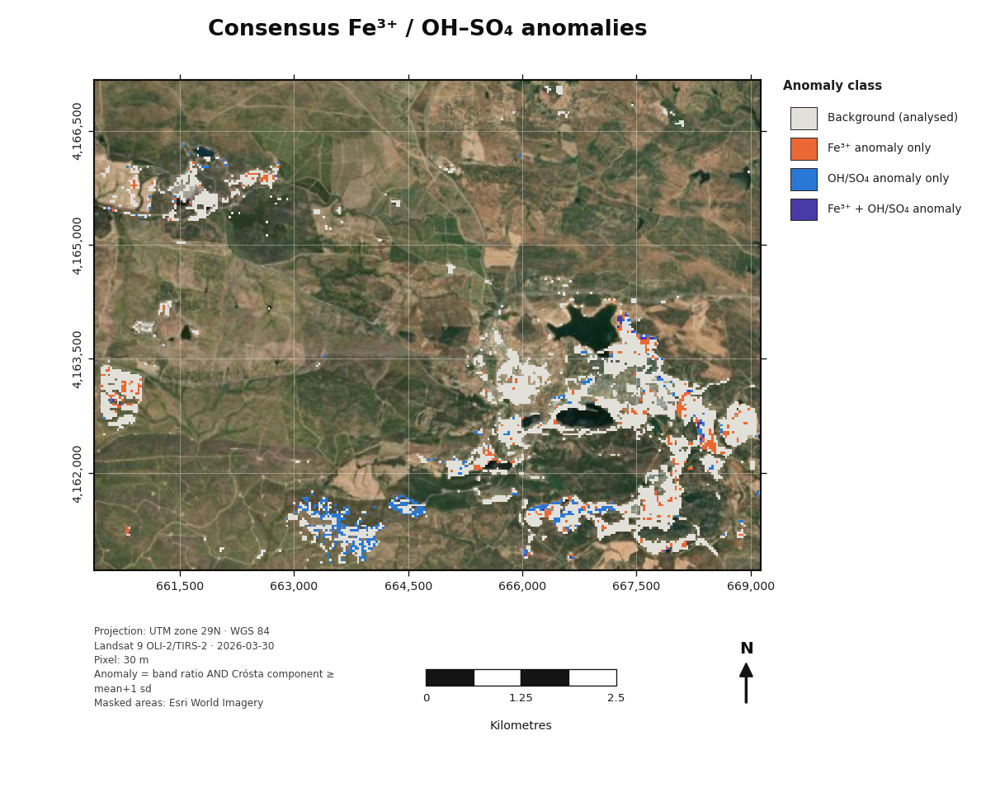

In [ ]:
LVL1, LVL2 = f"mean+{SIGMA_LEVELS[0]:g}sd", f"mean+{SIGMA_LEVELS[-1]:g}sd"
FE_ANOM = MASK_MIN & (IDX["Fe3_B4B2"] >= THR["Fe3_B4B2"][LVL1]) & (CR_FE["image"] >= THR["Crosta_Fe"][LVL1])
OH_ANOM = MASK_MIN & (IDX["OH_SO4_B6B7"] >= THR["OH_SO4_B6B7"][LVL1]) & (CR_OH["image"] >= THR["Crosta_OH"][LVL1])

OVERLAP = np.full((H, W), -1, dtype=np.int16)
OVERLAP[MASK_MIN] = 0
OVERLAP[FE_ANOM & ~OH_ANOM] = 1
OVERLAP[OH_ANOM & ~FE_ANOM] = 2
OVERLAP[FE_ANOM & OH_ANOM] = 3
OVERLAP_NAMES  = ["Background (analysed)", "Fe³⁺ anomaly only", "OH/SO₄ anomaly only", "Fe³⁺ + OH/SO₄ anomaly"]
OVERLAP_COLORS = ["#e1e0d9", "#eb6834", "#2a78d6", "#4a3aa7"]

ov_rows = []
for k, name in enumerate(OVERLAP_NAMES):
    n = int((OVERLAP == k).sum())
    ov_rows.append({"class": name, "pixels": n, "area_km2": round(n * PIXEL_AREA_KM2, 3),
                    "percent_of_analysed": round(100 * n / max(MASK_MIN.sum(), 1), 1)})
# strict version (last SIGMA_LEVELS value on both layers) for reporting
_fe2 = MASK_MIN & (IDX["Fe3_B4B2"] >= THR["Fe3_B4B2"][LVL2]) & (CR_FE["image"] >= THR["Crosta_Fe"][LVL2])
_oh2 = MASK_MIN & (IDX["OH_SO4_B6B7"] >= THR["OH_SO4_B6B7"][LVL2]) & (CR_OH["image"] >= THR["Crosta_OH"][LVL2])
ov_rows.append({"class": f"Fe³⁺ + OH/SO₄ anomaly (strict, {LVL2})", "pixels": int((_fe2 & _oh2).sum()),
                "area_km2": round((_fe2 & _oh2).sum() * PIXEL_AREA_KM2, 3),
                "percent_of_analysed": round(100 * (_fe2 & _oh2).sum() / max(MASK_MIN.sum(), 1), 1)})
OVERLAP_TABLE = pd.DataFrame(ov_rows)
OVERLAP_TABLE.to_csv(TABLE_DIR / "tab_06_overlap_classes.csv", index=False)
print(OVERLAP_TABLE.to_string(index=False))

fig = plot_categorical(OVERLAP, "Consensus Fe³⁺ / OH-SO₄ anomalies", OVERLAP_COLORS, OVERLAP_NAMES,
                       fname="fig_16_consensus_anomaly_overlap", key_title="Anomaly class",
                       extra=[f"Anomaly = band ratio AND Crósta component ≥ {LVL1.replace('sd', ' sd')}"])
plt.show()

## 11 · Unsupervised classification (K-means spectral domains)

The features are chosen to be **non-redundant** and **brightness-independent** where possible: log B4/B2,
log B4/B3, NIR Fe³⁺ depth, log B6/B5, log B6/B7 and log albedo (mean SR of B2–B7). Each is standardised. The
Crósta components are left out because they duplicate the ratios, and raw reflectance bands are left out because
they carry albedo several times over.

The number of clusters is **assessed, not assumed**. For each k in `K_RANGE` the notebook reports inertia (elbow),
the silhouette coefficient (higher is better; Rousseeuw, 1987) and the Davies–Bouldin index (lower is better).
Stability of the final solution is measured with the adjusted Rand index across random seeds (Hubert & Arabie,
1985). Clusters are **numbered by decreasing median B4/B2**, so cluster 1 is always the most Fe³⁺-rich. The "hint"
column describes each cluster statistically; it is not a mineral identification.

K-means features: log B4/B2, log B4/B3, NIR Fe depth, log B6/B5, log B6/B7, log albedo
Pixels in mineral mask: 5,145   usable (all features finite): 5,145
 k   inertia  silhouette  davies_bouldin
 3 19418.764       0.224           1.468
 4 17142.566       0.219           1.378
 5 15713.433       0.208           1.467
 6 14437.257       0.207           1.374
 7 13386.865       0.210           1.318
 8 12531.750       0.217           1.277
 9 11738.218       0.214           1.274
10 11104.019       0.206           1.326
Highest silhouette at k = 3;  k used = 6 (N_CLUSTERS in CONFIG)
  saved  fig_11a_kmeans_model_selection.png  +  fig_11a_kmeans_model_selection.pdf   (400 dpi)


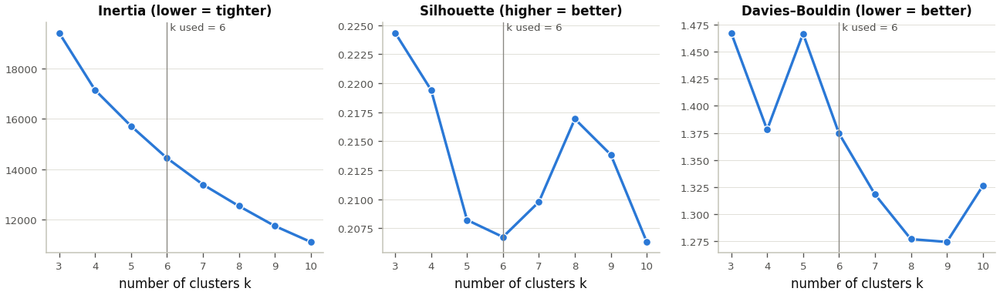

In [17]:
ALBEDO = np.full((H, W), np.nan, dtype="float32")
ALBEDO[INSIDE] = cube[1:7, INSIDE].mean(axis=0)                 # mean SR of B2–B7
FEAT = {
    "log B4/B2": np.log(IDX["Fe3_B4B2"]), "log B4/B3": np.log(IDX["Fe3_B4B3"]),
    "NIR Fe depth": IDX["FeCF_depthB5"], "log B6/B5": np.log(IDX["SWIR1_NIR_B6B5"]),
    "log B6/B7": np.log(IDX["OH_SO4_B6B7"]), "log albedo": np.log(mineral_layer(ALBEDO)),
}
if USE_LST_IN_KMEANS and LST is not None:
    FEAT["LST"] = mineral_layer(LST)
F_all = np.stack([FEAT[k][MASK_MIN] for k in FEAT], axis=-1)
ROW_OK = np.isfinite(F_all).all(axis=1)
print(f"K-means features: {', '.join(FEAT)}")
print(f"Pixels in mineral mask: {MASK_MIN.sum():,}   usable (all features finite): {ROW_OK.sum():,}")
F = StandardScaler().fit_transform(F_all[ROW_OK])

rng = np.random.default_rng(RANDOM_STATE)
sub = rng.choice(F.shape[0], min(F.shape[0], 20000), replace=False)
k_rows = []
for k in K_RANGE:
    km_k = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(F[sub])
    sil = silhouette_score(F[sub], km_k.labels_, sample_size=min(len(sub), 5000), random_state=RANDOM_STATE)
    k_rows.append({"k": k, "inertia": km_k.inertia_, "silhouette": sil,
                   "davies_bouldin": davies_bouldin_score(F[sub], km_k.labels_)})
K_TABLE = pd.DataFrame(k_rows)
K_TABLE.to_csv(TABLE_DIR / "tab_07_kmeans_model_selection.csv", index=False, float_format="%.4f")
k_best = int(K_TABLE.loc[K_TABLE["silhouette"].idxmax(), "k"])
K_USED = k_best if AUTO_K else N_CLUSTERS
print(K_TABLE.round(3).to_string(index=False))
print(f"Highest silhouette at k = {k_best};  k used = {K_USED} ({'AUTO_K' if AUTO_K else 'N_CLUSTERS in CONFIG'})")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, col, lab in zip(axes, ["inertia", "silhouette", "davies_bouldin"],
                        ["Inertia (lower = tighter)", "Silhouette (higher = better)", "Davies–Bouldin (lower = better)"]):
    ax.plot(K_TABLE["k"], K_TABLE[col], "-o", color=SERIES[0], lw=2, ms=6, mec="white", mew=0.8)
    ax.axvline(K_USED, color=MUTED, lw=0.8)
    ax.text(K_USED, ax.get_ylim()[1], f" k used = {K_USED}", va="top", ha="left", fontsize=8, color=INK_2)
    ax.set_xlabel("number of clusters k"); ax.set_title(lab, fontsize=10)
    style_chart(ax)
fig.tight_layout()
save_fig(fig, "fig_11a_kmeans_model_selection")
plt.show()

Stability across seeds: adjusted Rand index mean 0.955, min 0.916
 cluster  pixels  area_km2  percent  Fe³⁺ B4/B2  Fe³⁺ B4/B3 (blue-free)  NIR Fe³⁺ depth (B5)  SWIR1/NIR B6/B5  Gossan B6/B4  OH/SO₄ ± NPV B6/B7  albedo  NDVI                             hint
       1     817     0.735     15.9       2.316                   1.462                0.061            1.736         1.993               1.319   0.190 0.060                    NIR Fe³⁺ band
       2     846     0.761     16.4       2.253                   1.361               -0.206            1.250         1.784               1.240   0.218 0.172                           bright
       3    1313     1.182     25.5       2.213                   1.377               -0.260            1.396         2.236               1.412   0.174 0.234 OH/SO₄ high, residual vegetation
       4     729     0.656     14.2       2.175                   1.263               -0.074            1.271         1.508               1.287   0.125 0.089             

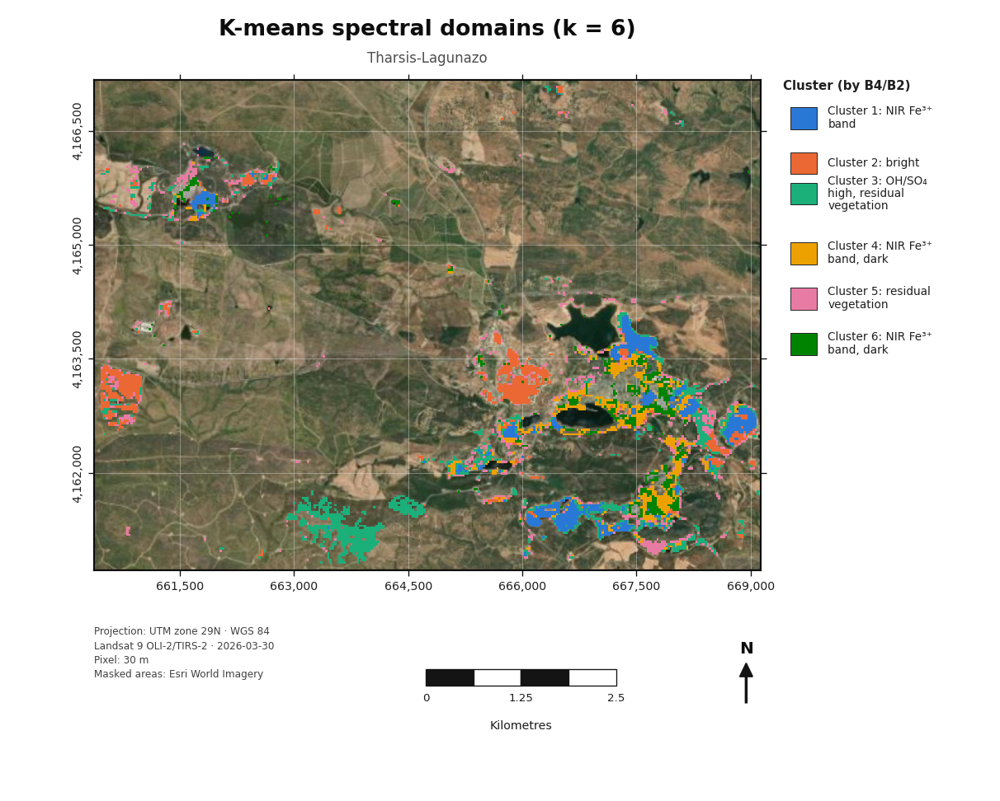

  saved  fig_11b_kmeans_cluster_facets.png  +  fig_11b_kmeans_cluster_facets.pdf   (400 dpi)


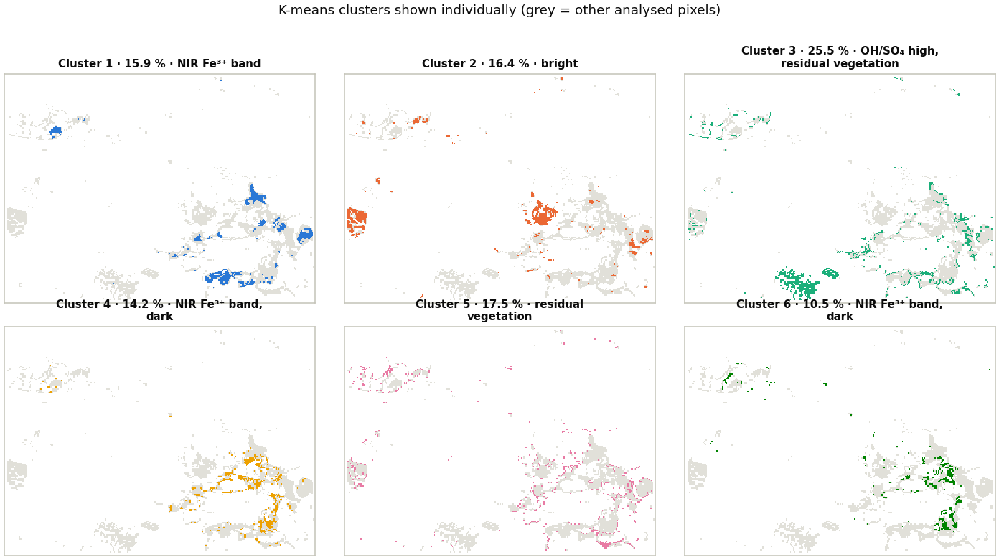

In [18]:
km = KMeans(n_clusters=K_USED, random_state=RANDOM_STATE, n_init=10).fit(F)
raw = km.labels_
fe_flat = IDX["Fe3_B4B2"][MASK_MIN][ROW_OK]
order = np.argsort([-np.nanmedian(fe_flat[raw == c]) for c in range(K_USED)])
remap = np.empty(K_USED, dtype=int); remap[order] = np.arange(K_USED)
lab_flat = remap[raw]

labels = np.full((H, W), -1, dtype=np.int16)
_mm_idx = np.flatnonzero(MASK_MIN.ravel())[ROW_OK]
labels.flat[_mm_idx] = lab_flat

aris = []
for seed in [s for s in range(5) if s != RANDOM_STATE]:
    alt = KMeans(n_clusters=K_USED, random_state=seed, n_init=10).fit(F).labels_
    aris.append(adjusted_rand_score(raw, alt))
print(f"Stability across seeds: adjusted Rand index mean {np.mean(aris):.3f}, min {np.min(aris):.3f}"
      + ("   (below 0.8: the partition is not stable - fewer clusters may be more defensible)" if np.min(aris) < 0.8 else ""))

CLUSTER_COLORS = [SERIES[i % len(SERIES)] for i in range(K_USED)]
if K_USED > len(SERIES):
    print("NOTE: more clusters than distinct categorical colours - read the class key and table, not colour alone.")

ref = {k: FEAT[k][MASK_MIN][ROW_OK] for k in FEAT}
def _zrob(x, allv):
    q1, med, q3 = np.nanpercentile(allv, [25, 50, 75]); s = (q3 - q1) / 1.349
    return (x - med) / s if s > 0 else 0.0
ndvi_flat = NDVI[MASK_MIN][ROW_OK]
cl_rows = []
for c in range(K_USED):
    m = lab_flat == c
    row = {"cluster": c + 1, "pixels": int(m.sum()), "area_km2": round(m.sum() * PIXEL_AREA_KM2, 3),
           "percent": round(100 * m.sum() / len(lab_flat), 1)}
    for k in IDX:
        row[IDX_LABEL[k]] = float(np.nanmedian(IDX[k][MASK_MIN][ROW_OK][m]))
    row["albedo"] = float(np.nanmedian(ALBEDO[MASK_MIN][ROW_OK][m]))
    row["NDVI"] = float(np.nanmedian(ndvi_flat[m]))
    hints = []
    if _zrob(np.median(ref["log B4/B2"][m]), ref["log B4/B2"]) >= 0.5: hints.append("Fe³⁺ high")
    if _zrob(np.median(ref["log B6/B7"][m]), ref["log B6/B7"]) >= 0.5: hints.append("OH/SO₄ high")
    if _zrob(np.median(ref["NIR Fe depth"][m]), ref["NIR Fe depth"]) >= 0.5: hints.append("NIR Fe³⁺ band")
    za = _zrob(np.median(ref["log albedo"][m]), ref["log albedo"])
    if za <= -0.5: hints.append("dark")
    if za >= 0.5: hints.append("bright")
    if _zrob(np.median(ndvi_flat[m]), ndvi_flat) >= 0.5: hints.append("residual vegetation")
    row["hint"] = ", ".join(hints) if hints else "near median"
    cl_rows.append(row)
CLUSTER_TABLE = pd.DataFrame(cl_rows)
CLUSTER_TABLE.to_csv(TABLE_DIR / "tab_08_kmeans_clusters.csv", index=False, float_format="%.4f")
print(CLUSTER_TABLE.round(3).to_string(index=False))

fig = plot_categorical(labels, f"K-means spectral domains (k = {K_USED})\n{SITE_NAME}", CLUSTER_COLORS,
                       [f"Cluster {i+1}: {h}" for i, h in enumerate(CLUSTER_TABLE["hint"])],
                       fname="fig_11_kmeans_classification", key_title="Cluster (by B4/B2)")
plt.show()

# facets: one panel per cluster, so identity never relies on colour alone
ncol = 3; nrow = int(math.ceil(K_USED / ncol))
aspect = (EXTENT[3] - EXTENT[2]) / (EXTENT[1] - EXTENT[0])
fig, axes = plt.subplots(nrow, ncol, figsize=(4.0 * ncol, 4.0 * nrow * aspect + 0.8), squeeze=False)
for c, ax in enumerate(axes.ravel()):
    if c >= K_USED:
        ax.axis("off"); continue
    show = np.full((H, W, 3), 1.0, dtype="float32")
    show[MASK_MIN] = mpl.colors.to_rgb("#e1e0d9")
    show[labels == c] = mpl.colors.to_rgb(CLUSTER_COLORS[c])
    ax.imshow(show, extent=EXTENT, origin="upper", interpolation="nearest")
    ax.set_title("\n".join(textwrap.wrap(f"Cluster {c+1} · {CLUSTER_TABLE.loc[c, 'percent']} % · "
                                         f"{CLUSTER_TABLE.loc[c, 'hint']}", 38)), fontsize=9, color=INK)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_edgecolor("#c3c2b7")
fig.suptitle("K-means clusters shown individually (grey = other analysed pixels)", fontsize=11, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.95), h_pad=2.0)
save_fig(fig, "fig_11b_kmeans_cluster_facets")
plt.show()

## 12 · Per-cluster reflectance spectra

The median spectrum of each cluster, with its interquartile range, is the spectral evidence behind the
classification. Shaded zones mark where the diagnostic absorptions sit relative to the OLI bands:
Fe³⁺ charge transfer (B1–B2), the Fe³⁺ crystal-field band (between B4 and B6, sampled only by B5) and the OH/SO₄
absorptions inside B7.

  saved  fig_12_class_median_spectra.png  +  fig_12_class_median_spectra.pdf   (400 dpi)


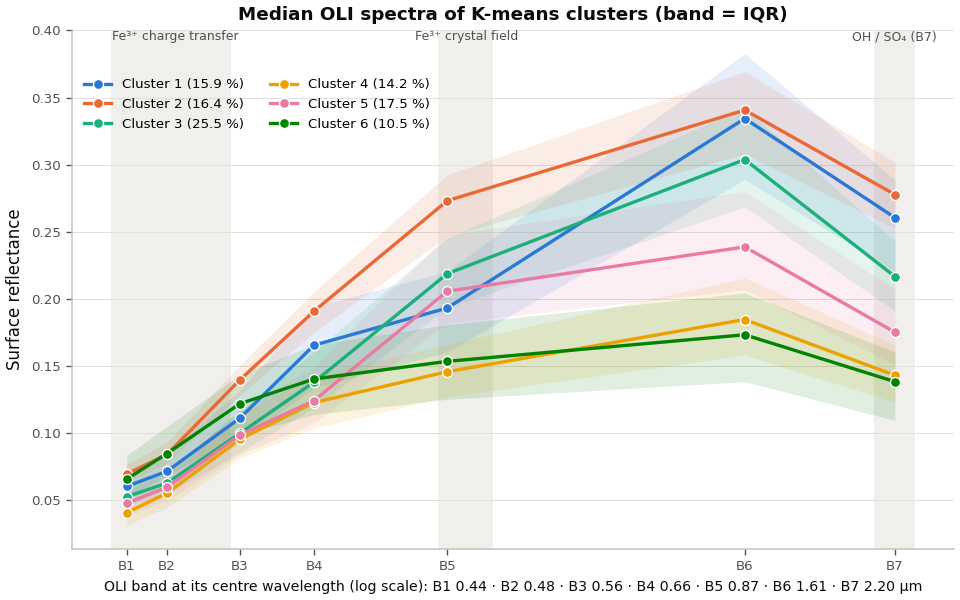

In [19]:
wl = np.array([OLI_WL[b] for b in range(1, 8)])
fig, ax = plt.subplots(figsize=(8.2, 5.2))
for lo_, hi_, txt in [(0.43, 0.55, "Fe³⁺ charge transfer"), (0.85, 0.95, "Fe³⁺ crystal field"),
                      (2.11, 2.29, "OH / SO₄ (B7)")]:
    ax.axvspan(lo_, hi_, color="#f0efec", zorder=0)
    ax.text((lo_ + hi_) / 2, 1.0, txt, transform=ax.get_xaxis_transform(), ha="center", va="top",
            fontsize=7.5, color=INK_2)
for c in range(K_USED):
    m = labels == c
    if m.sum() == 0:
        continue
    spec = np.stack([R[b][m] for b in range(1, 8)])
    q1, med, q3 = np.percentile(spec, [25, 50, 75], axis=1)
    ax.fill_between(wl, q1, q3, color=CLUSTER_COLORS[c], alpha=0.12, lw=0)
    ax.plot(wl, med, "-o", color=CLUSTER_COLORS[c], lw=2, ms=6, mec="white", mew=0.8,
            label=f"Cluster {c+1} ({CLUSTER_TABLE.loc[c, 'percent']} %)")
ax.set_xscale("log")
ax.set_xlabel("OLI band at its centre wavelength (log scale): B1 0.44 · B2 0.48 · B3 0.56 · B4 0.66 · B5 0.87 · B6 1.61 · B7 2.20 µm",
              fontsize=8.5)
ax.set_ylabel("Surface reflectance")
ax.set_title("Median OLI spectra of K-means clusters (band = IQR)", fontsize=11)
ax.set_xticks(wl); ax.set_xticklabels([f"B{b}" for b in range(1, 8)], fontsize=8)
ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
style_chart(ax)
ax.legend(fontsize=8, ncol=2, loc="upper left", bbox_to_anchor=(0.0, 0.93))
fig.tight_layout()
save_fig(fig, "fig_12_class_median_spectra")
plt.show()

## 13 · Spectral Angle Mapper: image endmember

SAM measures the angle (radians) between each pixel spectrum and a reference, independent of brightness (Kruse et al., 1993).

Image endmember: top 5 % of B4/B2 AND Crósta Fe; n = 102 px
Endmember reflectance B1..B7: [0.046 0.059 0.111 0.162 0.208 0.264 0.197]
  saved  fig_13_sam_image_endmember.png  +  fig_13_sam_image_endmember.pdf   (400 dpi)


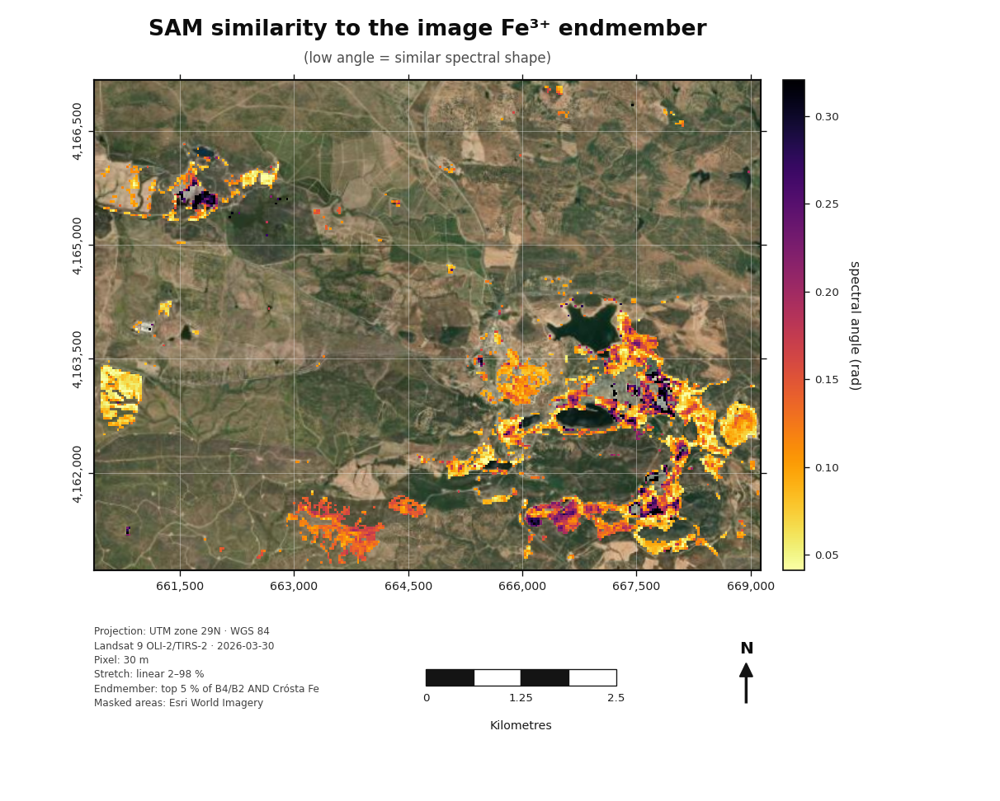

In [20]:
def sam_angle(flat, ref):
    ref = np.asarray(ref, float)
    num = flat @ ref
    den = np.linalg.norm(flat, axis=1) * np.linalg.norm(ref)
    with np.errstate(divide="ignore", invalid="ignore"):
        cos = np.clip(num / den, -1, 1)
    return np.arccos(cos)

_t_ratio = np.nanpercentile(IDX["Fe3_B4B2"][MASK_MIN], 95)
_t_pc = np.nanpercentile(CR_FE["image"][MASK_MIN], 95)
EM_SEL = MASK_MIN & (IDX["Fe3_B4B2"] >= _t_ratio) & (CR_FE["image"] >= _t_pc)
em_rule = "top 5 % of B4/B2 AND Crósta Fe"
if EM_SEL.sum() < 20:
    EM_SEL = MASK_MIN & (IDX["Fe3_B4B2"] >= _t_ratio); em_rule = "top 5 % of B4/B2 (too few joint pixels)"
ENDMEMBER = np.median(cube[:, EM_SEL], axis=1)
print(f"Image endmember: {em_rule}; n = {EM_SEL.sum():,} px")
print("Endmember reflectance B1..B7:", np.round(ENDMEMBER, 3))

flat_min = cube[:, MASK_MIN].T.astype("float64")
SAM_IMG = np.full((H, W), np.nan, dtype="float32")
SAM_IMG[MASK_MIN] = sam_angle(flat_min, ENDMEMBER)
fig = plot_single_band(SAM_IMG, "SAM similarity to the image Fe³⁺ endmember\n(low angle = similar spectral shape)",
                       "spectral angle (rad)", cmap="inferno_r", fname="fig_13_sam_image_endmember",
                       extra=[f"Endmember: {em_rule}"])
plt.show()

### 13·b · SAM against spectral-library endmembers (optional)

Provide **either** `LIBRARY_CSV` (columns `mineral,B1,…,B7`, reflectance already averaged to OLI bands, e.g.
exported from your EnMAP library notebook) **or** USGS Spectral Library v7 ASCII spectra (`USGS_SPECTRA`) with
their wavelength file (`USGS_WAVELENGTH_FILE`). The USGS data release (Kokaly et al., 2017) also includes
versions already resampled to Landsat 8 OLI. Suggested endmembers for this setting: jarosite, goethite, hematite,
kaolinite, muscovite/illite, alunite and gypsum.

USGS ASCII spectra are averaged over the USGS OLI band limits, a **boxcar approximation** of the relative
spectral response. Deleted channels (−1.23 × 10³⁴) are ignored. The notebook first prints the **angle between
every pair of library endmembers** at OLI resolution. Pairs closer than `SAM_MAX_ANGLE` cannot be separated by SAM
in this scene. Pixels whose best and second-best endmembers lie within `SAM_AMBIGUITY_MARGIN` of each other are
mapped as *ambiguous* rather than being forced into one class.

In [21]:
def _read_numeric_column(path):
    vals = []
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        for line in f:
            tok = line.strip().split()
            if not tok:
                continue
            try:
                vals.append(float(tok[0]))
            except ValueError:
                continue                                   # header / text lines
    a = np.array(vals, dtype=float)
    a[a < -1e30] = np.nan                                  # USGS deleted channels
    return a

def resample_to_oli(wavelength, reflectance):
    wl_ = np.asarray(wavelength, float); rf = np.asarray(reflectance, float)
    if np.nanmax(wl_) > 100:                               # nm -> µm
        wl_ = wl_ / 1000.0
    ok = np.isfinite(wl_) & np.isfinite(rf)
    wl_, rf = wl_[ok], rf[ok]
    o = np.argsort(wl_); wl_, rf = wl_[o], rf[o]
    out = []
    for b in range(1, 8):
        lo_, hi_ = OLI_BAND_EDGES[b]
        m = (wl_ >= lo_) & (wl_ <= hi_)
        if m.sum() >= 2:
            out.append(rf[m].mean())
        else:
            if (lo_ + hi_) / 2 < wl_.min() or (lo_ + hi_) / 2 > wl_.max():
                print(f"  WARNING: spectrum does not cover B{b}")
            out.append(np.interp((lo_ + hi_) / 2, wl_, rf))
    return np.array(out)

LIBRARY = {}
if LIBRARY_CSV:
    _lib = pd.read_csv(LIBRARY_CSV)
    _bcols = [f"B{b}" for b in range(1, 8)]
    missing = [c for c in ["mineral"] + _bcols if c not in _lib.columns]
    if missing:
        raise ValueError(f"LIBRARY_CSV is missing columns: {missing}")
    for _, r_ in _lib.iterrows():
        LIBRARY[str(r_["mineral"])] = r_[_bcols].to_numpy(dtype=float)
if USGS_SPECTRA:
    if not USGS_WAVELENGTH_FILE:
        raise ValueError("USGS_SPECTRA needs USGS_WAVELENGTH_FILE (the wavelength file of the same spectrometer/version)")
    _wl = _read_numeric_column(USGS_WAVELENGTH_FILE)
    for name, path in USGS_SPECTRA.items():
        _rf = _read_numeric_column(path)
        if _rf.size != _wl.size:
            raise ValueError(f"{name}: {_rf.size} values but the wavelength file has {_wl.size}")
        LIBRARY[name] = resample_to_oli(_wl, _rf)

SAM_LIB_CLASS = None
if not LIBRARY:
    print("Library SAM skipped: set LIBRARY_CSV or USGS_SPECTRA (+ USGS_WAVELENGTH_FILE) in CONFIG.")
else:
    names = list(LIBRARY)
    if len(names) > len(SERIES):
        print(f"NOTE: {len(names)} endmembers; only {len(SERIES)} distinct colours - use the table and facets.")
    LIB_TABLE = pd.DataFrame([{"mineral": n, **{f"B{b}": LIBRARY[n][b-1] for b in range(1, 8)}} for n in names])
    LIB_TABLE.to_csv(TABLE_DIR / "tab_09_library_oli_bands.csv", index=False, float_format="%.4f")
    sep = np.array([[float(sam_angle(LIBRARY[a][None, :], LIBRARY[b])[0]) for b in names] for a in names])
    SEP_TABLE = pd.DataFrame(sep, index=names, columns=names)
    SEP_TABLE.to_csv(TABLE_DIR / "tab_10_library_separability_rad.csv", float_format="%.4f")
    print("Angle between library endmembers at OLI resolution (rad):")
    print(SEP_TABLE.round(3).to_string())
    close = [(a, b, sep[i, j]) for i, a in enumerate(names) for j, b in enumerate(names) if j > i and sep[i, j] < SAM_MAX_ANGLE]
    for a, b, s in close:
        print(f"  NOT SEPARABLE at SAM_MAX_ANGLE = {SAM_MAX_ANGLE}: {a} vs {b} ({s:.3f} rad)")

    ang = np.stack([sam_angle(flat_min, LIBRARY[n]) for n in names])          # (n_lib, N)
    order_ = np.argsort(ang, axis=0)
    best = order_[0]; best_ang = ang[best, np.arange(ang.shape[1])]
    second_ang = ang[order_[1], np.arange(ang.shape[1])] if len(names) > 1 else np.full_like(best_ang, np.inf)
    cls_flat = np.where(best_ang <= SAM_MAX_ANGLE, best, len(names) + 1)
    cls_flat = np.where((best_ang <= SAM_MAX_ANGLE) & (second_ang - best_ang < SAM_AMBIGUITY_MARGIN), len(names), cls_flat)
    SAM_LIB_CLASS = np.full((H, W), -1, dtype=np.int16)
    SAM_LIB_CLASS[MASK_MIN] = cls_flat
    lib_colors = [SERIES[i % len(SERIES)] for i in range(len(names))] + ["#898781", "#e1e0d9"]
    lib_labels = names + [f"Ambiguous (2 endmembers within {SAM_AMBIGUITY_MARGIN:g} rad)",
                          f"Unclassified (> {SAM_MAX_ANGLE:g} rad)"]
    rows = []
    for i, n in enumerate(lib_labels):
        cnt = int((cls_flat == i).sum())
        rows.append({"class": n, "pixels": cnt, "area_km2": round(cnt * PIXEL_AREA_KM2, 3),
                     "percent_of_analysed": round(100 * cnt / max(len(cls_flat), 1), 1),
                     "median_angle_rad": float(np.median(best_ang[cls_flat == i])) if cnt else np.nan})
    SAM_LIB_TABLE = pd.DataFrame(rows)
    SAM_LIB_TABLE.to_csv(TABLE_DIR / "tab_11_sam_library_classes.csv", index=False, float_format="%.4f")
    print(SAM_LIB_TABLE.to_string(index=False))

    fig, ax = plt.subplots(figsize=(7.6, 4.8))
    for i, n in enumerate(names):
        ax.plot(wl, LIBRARY[n], "-o", color=lib_colors[i], lw=2, ms=6, mec="white", mew=0.8, label=n)
    ax.plot(wl, ENDMEMBER, "-o", color=INK, lw=1.2, ms=5, mec="white", mew=0.6, label="image endmember (§13)")
    ax.set_xticks(wl); ax.set_xticklabels([f"B{b}" for b in range(1, 8)])
    ax.set_xlabel("OLI band"); ax.set_ylabel("Reflectance"); ax.set_title("Library endmembers at OLI resolution", fontsize=11)
    style_chart(ax); ax.legend(fontsize=8, ncol=2)
    fig.tight_layout(); save_fig(fig, "fig_17a_library_endmembers_oli"); plt.show()

    fig = plot_categorical(SAM_LIB_CLASS, "SAM classification: library endmembers", lib_colors, lib_labels,
                           fname="fig_17_sam_library_classes", key_title="Minimum angle",
                           extra=[f"Max angle {SAM_MAX_ANGLE:g} rad · spectral-shape similarity, not identification"])
    plt.show()
    ang_maps = []
    for i in range(len(names)):
        a_ = np.full((H, W), np.nan, dtype="float32"); a_[MASK_MIN] = ang[i]; ang_maps.append(a_)
    fig = panel_maps(ang_maps, [f"Angle to {n}" for n in names], ["inferno_r"] * len(names),
                     "SAM angle to each library endmember (dark = similar)", fname="fig_17b_sam_library_angles",
                     cbar_labels=["rad"] * len(names))
    plt.show()

Library SAM skipped: set LIBRARY_CSV or USGS_SPECTRA (+ USGS_WAVELENGTH_FILE) in CONFIG.


## 14 · Robustness checks

Four questions decide how confidently the maps can be described in the thesis:

1. **Do independent methods agree?** Spearman rank correlations between all indices, and the Jaccard overlap of
   their top `TOP_PERCENT` % pixels. Two unrelated top-10 % masks overlap by only about 0.05.
2. **Does the Crósta result depend on the PCA variant?** Correlation- versus covariance-matrix PCA.
3. **Is residual vegetation still driving an index?** Spearman ρ between each index and NDVI inside the mineral
   mask. |ρ| ≥ 0.5 flags an index whose pattern partly tracks sparse vegetation below the NDVI threshold; the NIR
   depth index is expected to be flagged.
4. **How sensitive are the anomalies to the vegetation threshold?** The Fe³⁺ and OH/SO₄ anomaly areas are
   recomputed for each NDVI threshold in `NDVI_SENSITIVITY`, holding the index thresholds of §10 fixed.

  saved  fig_18_index_spearman_matrix.png  +  fig_18_index_spearman_matrix.pdf   (400 dpi)


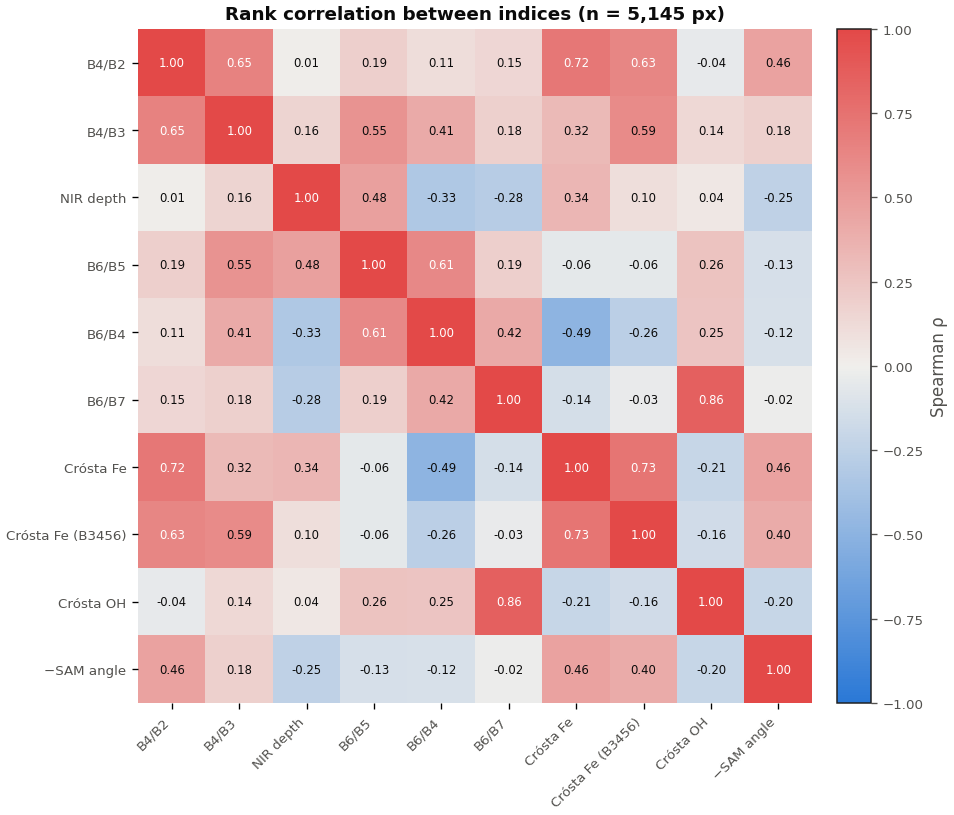

Index vs NDVI inside the mineral mask (|rho| >= 0.5 = residual vegetation still drives the index):
            index  spearman_rho_with_NDVI    n                 flag
            B4/B2                   0.024 5145                     
            B4/B3                   0.023 5145                     
        NIR depth                  -0.926 5145 vegetation-sensitive
            B6/B5                  -0.138 5145                     
            B6/B4                   0.635 5145 vegetation-sensitive
            B6/B7                   0.398 5145                     
        Crósta Fe                  -0.460 5145                     
Crósta Fe (B3456)                  -0.189 5145                     
        Crósta OH                   0.073 5145                     
       −SAM angle                   0.151 5145                     

                              comparison   layer_a           layer_b  spearman_rho  jaccard_top10pct  jaccard_if_unrelated
                     ratio vs

In [ ]:
ROBUST_LAYERS = {
    "B4/B2": IDX["Fe3_B4B2"], "B4/B3": IDX["Fe3_B4B3"], "NIR depth": IDX["FeCF_depthB5"],
    "B6/B5": IDX["SWIR1_NIR_B6B5"], "B6/B4": IDX["Gossan_B6B4"], "B6/B7": IDX["OH_SO4_B6B7"],
    "Crósta Fe": CR_FE["image"], "Crósta Fe (B3456)": CR_FE3["image"], "Crósta OH": CR_OH["image"],
    "-SAM angle": -SAM_IMG,
}
keys = list(ROBUST_LAYERS)
common = MASK_MIN.copy()
for a in ROBUST_LAYERS.values():
    common &= np.isfinite(a)
idx_c = np.flatnonzero(common)
if idx_c.size > 50000:
    idx_c = np.random.default_rng(RANDOM_STATE).choice(idx_c, 50000, replace=False)
M = np.stack([ROBUST_LAYERS[k].ravel()[idx_c] for k in keys], axis=1)
RHO = np.asarray(stats.spearmanr(M)[0], dtype=float)
RHO_TABLE = pd.DataFrame(RHO, index=keys, columns=keys)
RHO_TABLE.to_csv(TABLE_DIR / "tab_12_spearman_matrix.csv", float_format="%.3f")

fig, ax = plt.subplots(figsize=(8.4, 7.0))
im = ax.imshow(RHO, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(keys))); ax.set_xticklabels(keys, rotation=45, ha="right", fontsize=8, color=INK_2)
ax.set_yticks(range(len(keys))); ax.set_yticklabels(keys, fontsize=8, color=INK_2)
for i in range(len(keys)):
    for j in range(len(keys)):
        ax.text(j, i, f"{RHO[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(RHO[i, j]) > 0.6 else INK)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.set_label("Spearman ρ", color=INK_2)
cb.ax.tick_params(colors=INK_2)
ax.set_title(f"Rank correlation between indices (n = {idx_c.size:,} px)", fontsize=11, color=INK)
fig.tight_layout(); save_fig(fig, "fig_18_index_spearman_matrix"); plt.show()

def top_mask(arr, pct=TOP_PERCENT, mask=MASK_MIN):
    ok = mask & np.isfinite(arr)
    t = np.percentile(arr[ok], 100 - pct)
    return ok & (arr >= t)

def jaccard(a, b):
    u = (a | b).sum()
    return float((a & b).sum() / u) if u else np.nan

pairs = [("B4/B2", "Crósta Fe", "ratio vs PCA (Fe³⁺)"), ("B4/B2", "B4/B3", "blue vs blue-free ratio"),
         ("Crósta Fe", "Crósta Fe (B3456)", "blue vs blue-free Crósta"), ("B6/B7", "Crósta OH", "ratio vs PCA (OH/SO₄)"),
         ("B4/B2", "-SAM angle", "ratio vs SAM (image endmember)"), ("B4/B2", "B6/B7", "Fe³⁺ vs OH/SO₄")]
p = TOP_PERCENT / 100
agree_rows = [{"comparison": lab, "layer_a": a, "layer_b": b,
               "spearman_rho": RHO_TABLE.loc[a, b],
               f"jaccard_top{TOP_PERCENT}pct": jaccard(top_mask(ROBUST_LAYERS[a]), top_mask(ROBUST_LAYERS[b])),
               "jaccard_if_unrelated": p * p / (2 * p - p * p)} for a, b, lab in pairs]

cr_alt_fe = crosta_fpcs([2, 4, 5, 6], (2, 4), 4, "iron oxides (other PCA variant)", standardise=not CROSTA_STANDARDISE, verbose=False)
cr_alt_oh = crosta_fpcs([2, 5, 6, 7], (6, 7), 6, "hydroxyls (other PCA variant)", standardise=not CROSTA_STANDARDISE, verbose=False)
for base_, alt_, lab in [(CR_FE, cr_alt_fe, "Crósta Fe: correlation vs covariance PCA"),
                         (CR_OH, cr_alt_oh, "Crósta OH: correlation vs covariance PCA")]:
    agree_rows.append({"comparison": lab, "layer_a": f"PC{base_['pc']+1}", "layer_b": f"PC{alt_['pc']+1}",
                       "spearman_rho": spearman_layers(base_["image"], alt_["image"])[0],
                       f"jaccard_top{TOP_PERCENT}pct": jaccard(top_mask(base_["image"]), top_mask(alt_["image"])),
                       "jaccard_if_unrelated": p * p / (2 * p - p * p)})
AGREE_TABLE = pd.DataFrame(agree_rows)

# residual-vegetation check: correlation of every index with NDVI inside the mineral mask
veg_rows = []
for k_, a_ in ROBUST_LAYERS.items():
    rho_, n_ = spearman_layers(a_, NDVI, mask=MASK_MIN)
    veg_rows.append({"index": k_, "spearman_rho_with_NDVI": rho_, "n": n_,
                     "flag": "vegetation-sensitive" if np.isfinite(rho_) and abs(rho_) >= 0.5 else ""})
VEG_CHECK = pd.DataFrame(veg_rows)
VEG_CHECK.to_csv(TABLE_DIR / "tab_13b_index_vs_ndvi.csv", index=False, float_format="%.3f")
print("Index vs NDVI inside the mineral mask (|rho| >= 0.5 = residual vegetation still drives the index):")
print(VEG_CHECK.round(3).to_string(index=False))
print()
AGREE_TABLE.to_csv(TABLE_DIR / "tab_13_method_agreement.csv", index=False, float_format="%.3f")
print(AGREE_TABLE.round(3).to_string(index=False))

Index thresholds held fixed: B4/B2 >= 2.464, B6/B7 >= 1.426 (mean+1sd at NDVI 0.3)
 ndvi_threshold  analysed_km2  fe_anomaly_km2  oh_anomaly_km2  jaccard_fe_vs_config  jaccard_oh_vs_config
           0.20         2.749           0.454           0.195                 0.757                 0.285
           0.25         3.569           0.538           0.337                 0.898                 0.491
           0.30         4.630           0.599           0.686                 1.000                 1.000
           0.35         5.883           0.629           1.218                 0.953                 0.563
           0.40         7.464           0.654           2.089                 0.916                 0.328
  saved  fig_19_ndvi_threshold_sensitivity.png  +  fig_19_ndvi_threshold_sensitivity.pdf   (400 dpi)


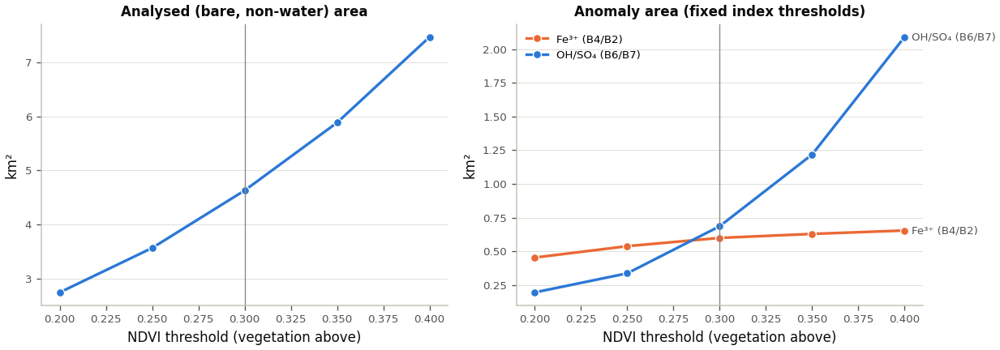

In [23]:
t_fe, t_oh = THR["Fe3_B4B2"][LVL1], THR["OH_SO4_B6B7"][LVL1]
base_fe = MASK_MIN & (IDX["Fe3_B4B2"] >= t_fe)
base_oh = MASK_MIN & (IDX["OH_SO4_B6B7"] >= t_oh)
sens_rows = []
for t in NDVI_SENSITIVITY:
    m = BASE_NOVEG & (NDVI <= t)
    fe = m & (RAW_IDX["Fe3_B4B2"] >= t_fe)
    oh = m & (RAW_IDX["OH_SO4_B6B7"] >= t_oh)
    sens_rows.append({"ndvi_threshold": t, "analysed_km2": m.sum() * PIXEL_AREA_KM2,
                      "fe_anomaly_km2": fe.sum() * PIXEL_AREA_KM2, "oh_anomaly_km2": oh.sum() * PIXEL_AREA_KM2,
                      "jaccard_fe_vs_config": jaccard(fe, base_fe), "jaccard_oh_vs_config": jaccard(oh, base_oh)})
SENS_TABLE = pd.DataFrame(sens_rows)
SENS_TABLE.to_csv(TABLE_DIR / "tab_14_ndvi_sensitivity.csv", index=False, float_format="%.4f")
print(f"Index thresholds held fixed: B4/B2 >= {t_fe:.3f}, B6/B7 >= {t_oh:.3f} ({LVL1} at NDVI {NDVI_VEG_THRESHOLD:g})")
print(SENS_TABLE.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
ax = axes[0]
ax.plot(SENS_TABLE["ndvi_threshold"], SENS_TABLE["analysed_km2"], "-o", color=SERIES[0], lw=2, ms=6, mec="white", mew=0.8)
ax.set_title("Analysed (bare, non-water) area", fontsize=10); ax.set_ylabel("km²")
ax2 = axes[1]
for col, color, lab in [("fe_anomaly_km2", SERIES[1], "Fe³⁺ (B4/B2)"), ("oh_anomaly_km2", SERIES[0], "OH/SO₄ (B6/B7)")]:
    ax2.plot(SENS_TABLE["ndvi_threshold"], SENS_TABLE[col], "-o", color=color, lw=2, ms=6, mec="white", mew=0.8, label=lab)
    ax2.annotate(lab, (SENS_TABLE["ndvi_threshold"].iloc[-1], SENS_TABLE[col].iloc[-1]), xytext=(5, 0),
                 textcoords="offset points", va="center", fontsize=8, color=INK_2)
ax2.set_title("Anomaly area (fixed index thresholds)", fontsize=10); ax2.set_ylabel("km²")
ax2.legend(fontsize=8, loc="upper left")
for a_ in axes:
    a_.axvline(NDVI_VEG_THRESHOLD, color=MUTED, lw=0.8)
    a_.set_xlabel("NDVI threshold (vegetation above)")
    style_chart(a_)
fig.tight_layout(); save_fig(fig, "fig_19_ndvi_threshold_sensitivity"); plt.show()

## 15 · Validation against field samples and EnMAP (optional)

**Samples.** Each index is averaged over a `SAMPLE_WINDOW` × `SAMPLE_WINDOW` pixel window (mineral-mask pixels
only) around every sample and compared with the sample attributes using Spearman's ρ. For a class column (e.g.
FTIR jarosite present / absent, or tailings vs slag) the notebook draws box plots and runs a Mann–Whitney U test
(two groups) or a Kruskal–Wallis test (more than two). Points and pixels do not match in support: a hand sample
represents centimetres, a pixel 900 m² of mixed surface, and sampling and image dates differ. Read ρ as
*consistency*, not calibration, and report n.

**EnMAP.** Each raster is resampled (area-weighted average) onto the Landsat grid. Correlations are computed on
every third pixel in each direction, which reduces the inflation of significance from spatial autocorrelation.
The Jaccard overlap of the top `TOP_PERCENT` % is reported as well.

In [ ]:
VAL_LAYERS = {"B4/B2": IDX["Fe3_B4B2"], "B4/B3": IDX["Fe3_B4B3"], "NIR depth": IDX["FeCF_depthB5"],
              "B6/B5": IDX["SWIR1_NIR_B6B5"], "B6/B4": IDX["Gossan_B6B4"], "B6/B7": IDX["OH_SO4_B6B7"],
              "Crósta Fe": CR_FE["image"], "Crósta OH": CR_OH["image"], "-SAM angle": -SAM_IMG}
SAMPLES = None
if not SAMPLES_CSV:
    print("Sample validation skipped: set SAMPLES_CSV (and SAMPLE_VALUE_COLS / SAMPLE_CLASS_COL) in CONFIG.")
else:
    SAMPLES = pd.read_csv(SAMPLES_CSV)
    xs = SAMPLES[SAMPLE_X_COL].astype(float).to_numpy(); ys = SAMPLES[SAMPLE_Y_COL].astype(float).to_numpy()
    if SAMPLE_CRS and rasterio.crs.CRS.from_user_input(SAMPLE_CRS) != CRS:
        xs, ys = warp_transform(SAMPLE_CRS, CRS, xs, ys); xs, ys = np.asarray(xs), np.asarray(ys)
    rows_, cols_ = rasterio.transform.rowcol(TRANSFORM, xs, ys)
    rows_, cols_ = np.asarray(rows_), np.asarray(cols_)
    half = SAMPLE_WINDOW // 2
    SAMPLES["inside_grid"] = (rows_ >= 0) & (rows_ < H) & (cols_ >= 0) & (cols_ < W)
    n_px = []
    for key, arr in VAL_LAYERS.items():
        vals = []
        for r0, c0 in zip(rows_, cols_):
            win = arr[max(r0 - half, 0):max(min(r0 + half + 1, H), 0), max(c0 - half, 0):max(min(c0 + half + 1, W), 0)]
            vals.append(float(np.nanmean(win)) if win.size and np.isfinite(win).any() else np.nan)
        SAMPLES[key] = vals
    for r0, c0 in zip(rows_, cols_):
        win = MASK_MIN[max(r0 - half, 0):max(min(r0 + half + 1, H), 0), max(c0 - half, 0):max(min(c0 + half + 1, W), 0)]
        n_px.append(int(win.sum()))
    SAMPLES["analysed_px_in_window"] = n_px
    SAMPLES.to_csv(TABLE_DIR / "tab_15_samples_with_index_values.csv", index=False, float_format="%.5f")
    n_valid = int(np.isfinite(SAMPLES["B4/B2"]).sum())
    print(f"Samples: {len(SAMPLES)} read, {int(SAMPLES['inside_grid'].sum())} inside the grid, "
          f"{n_valid} with analysed pixels in the {SAMPLE_WINDOW}x{SAMPLE_WINDOW} window")
    if n_valid < 10:
        print("  NOTE: fewer than 10 usable samples - correlations are not meaningful.")

    corr_rows = []
    for vc in SAMPLE_VALUE_COLS:
        for key in VAL_LAYERS:
            ok = np.isfinite(SAMPLES[key]) & np.isfinite(pd.to_numeric(SAMPLES[vc], errors="coerce"))
            if ok.sum() >= 5:
                rho, pval = stats.spearmanr(SAMPLES.loc[ok, key], pd.to_numeric(SAMPLES.loc[ok, vc]))
            else:
                rho, pval = np.nan, np.nan
            corr_rows.append({"attribute": vc, "index": key, "n": int(ok.sum()), "spearman_rho": rho, "p_value": pval})
    if corr_rows:
        SAMPLE_CORR = pd.DataFrame(corr_rows)
        SAMPLE_CORR.to_csv(TABLE_DIR / "tab_16_sample_spearman.csv", index=False, float_format="%.4f")
        print(SAMPLE_CORR.round(3).to_string(index=False))
        main = ["B4/B2", "B6/B7", "Crósta Fe", "Crósta OH"]
        vcs = SAMPLE_VALUE_COLS[:3]
        fig, axes = plt.subplots(len(vcs), len(main), figsize=(3.1 * len(main), 2.8 * len(vcs)), squeeze=False)
        for i, vc in enumerate(vcs):
            for j, key in enumerate(main):
                ax = axes[i, j]
                yv = pd.to_numeric(SAMPLES[vc], errors="coerce")
                ok = np.isfinite(SAMPLES[key]) & np.isfinite(yv)
                ax.scatter(SAMPLES.loc[ok, key], yv[ok], s=30, color=SERIES[0], edgecolor="white", linewidth=0.8)
                r_ = SAMPLE_CORR[(SAMPLE_CORR.attribute == vc) & (SAMPLE_CORR["index"] == key)].iloc[0]
                ax.set_title(f"ρ = {r_.spearman_rho:.2f} (n = {r_.n})", fontsize=8.5, color=INK)
                ax.set_xlabel(key, fontsize=8); ax.set_ylabel(vc if j == 0 else "", fontsize=8)
                style_chart(ax, grid_axis="both")
        fig.suptitle("Landsat indices vs sample attributes", fontsize=11, color=INK)
        fig.tight_layout(rect=(0, 0, 1, 0.96)); save_fig(fig, "fig_20_samples_scatter"); plt.show()

    if SAMPLE_CLASS_COL:
        grp = SAMPLES[SAMPLE_CLASS_COL].astype(str)
        levels = sorted(grp.unique())
        test_rows = []
        main = ["B4/B2", "B6/B7", "Crósta Fe", "Crósta OH"]
        fig, axes = plt.subplots(1, len(main), figsize=(3.1 * len(main), 3.4), squeeze=False)
        for j, key in enumerate(main):
            data = [SAMPLES.loc[(grp == g) & np.isfinite(SAMPLES[key]), key].to_numpy() for g in levels]
            ax = axes[0, j]
            ax.boxplot([d if len(d) else np.array([np.nan]) for d in data], widths=0.5, patch_artist=True,
                       boxprops=dict(facecolor="#cde2fb", edgecolor=SERIES[0]), medianprops=dict(color=INK, lw=1.5),
                       whiskerprops=dict(color=SERIES[0]), capprops=dict(color=SERIES[0]),
                       flierprops=dict(marker="o", ms=4, markerfacecolor=SERIES[0], markeredgecolor="white"))
            ax.set_xticks(range(1, len(levels) + 1)); ax.set_xticklabels([f"{g}\n(n={len(d)})" for g, d in zip(levels, data)], fontsize=8)
            ax.set_title(key, fontsize=10); ax.set_xlabel(SAMPLE_CLASS_COL, fontsize=8)
            style_chart(ax)
            usable = [d for d in data if len(d) >= 3]
            if len(usable) == 2 and len(levels) == 2:
                stat, pval = stats.mannwhitneyu(usable[0], usable[1], alternative="two-sided"); test = "Mann–Whitney U"
            elif len(usable) >= 3:
                stat, pval = stats.kruskal(*usable); test = "Kruskal–Wallis H"
            else:
                stat, pval, test = np.nan, np.nan, "too few samples"
            test_rows.append({"index": key, "test": test, "statistic": stat, "p_value": pval,
                              **{f"median[{g}]": (np.median(d) if len(d) else np.nan) for g, d in zip(levels, data)}})
        fig.suptitle(f"Index values by {SAMPLE_CLASS_COL}", fontsize=11, color=INK)
        fig.tight_layout(rect=(0, 0, 1, 0.94)); save_fig(fig, "fig_21_samples_by_class"); plt.show()
        SAMPLE_TESTS = pd.DataFrame(test_rows)
        SAMPLE_TESTS.to_csv(TABLE_DIR / "tab_17_sample_group_tests.csv", index=False, float_format="%.4f")
        print(SAMPLE_TESTS.round(4).to_string(index=False))

    fig = plot_categorical(OVERLAP, "Samples over the consensus anomaly map", OVERLAP_COLORS, OVERLAP_NAMES,
                           fname="fig_22_samples_on_anomaly_map", key_title="Anomaly class", points=(xs, ys),
                           extra=[f"{len(SAMPLES)} samples (black dots)"])
    plt.show()

Sample validation skipped: set SAMPLES_CSV (and SAMPLE_VALUE_COLS / SAMPLE_CLASS_COL) in CONFIG.


In [25]:
ENMAP = {}
if not ENMAP_RASTERS:
    print("EnMAP comparison skipped: set ENMAP_RASTERS in CONFIG.")
else:
    en_rows = []
    thin = np.zeros((H, W), bool); thin[::3, ::3] = True
    for label, spec_ in ENMAP_RASTERS.items():
        path, band_ = (spec_, 1) if isinstance(spec_, (str, Path)) else (spec_[0], int(spec_[1]))
        arr = np.full((H, W), np.nan, dtype="float32")
        with rasterio.open(path) as src:
            reproject(source=rasterio.band(src, band_), destination=arr, src_transform=src.transform, src_crs=src.crs,
                      src_nodata=src.nodata, dst_transform=TRANSFORM, dst_crs=CRS, dst_nodata=np.nan,
                      resampling=Resampling.average)
        ENMAP[label] = arr
        ok = MASK_MIN & np.isfinite(arr)
        print(f"{label}: {int(ok.sum()):,} analysed Landsat pixels with EnMAP values")
        for key, lay in VAL_LAYERS.items():
            rho, n = spearman_layers(arr, lay, mask=ok & thin)
            en_rows.append({"enmap_layer": label, "landsat_index": key, "n_thinned": n, "spearman_rho": rho,
                            f"jaccard_top{TOP_PERCENT}pct": jaccard(top_mask(arr, mask=ok), top_mask(lay, mask=ok))})
        fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.0))
        for ax, key in zip(axes, ["B4/B2", "B6/B7"]):
            m = ok & thin & np.isfinite(VAL_LAYERS[key])
            if m.sum() < 10:
                ax.text(0.5, 0.5, "too few overlapping pixels", ha="center", va="center", transform=ax.transAxes, color=INK_2)
                continue
            hb = ax.hexbin(VAL_LAYERS[key][m], arr[m], gridsize=40, cmap=SEQ_BLUE, mincnt=1, linewidths=0)
            ax.set_xlabel(f"Landsat {key}"); ax.set_ylabel(label)
            r_ = [e for e in en_rows if e["enmap_layer"] == label and e["landsat_index"] == key][0]
            ax.set_title(f"ρ = {r_['spearman_rho']:.2f} (every 3rd pixel, n = {r_['n_thinned']:,})", fontsize=9.5)
            style_chart(ax, grid_axis="both")
            fig.colorbar(hb, ax=ax, fraction=0.046, pad=0.03).set_label("pixels", color=INK_2)
        fig.tight_layout()
        save_fig(fig, f"fig_23_enmap_vs_landsat_{re.sub(r'[^A-Za-z0-9]+', '_', label).strip('_')}")
        plt.show()
    ENMAP_TABLE = pd.DataFrame(en_rows)
    ENMAP_TABLE.to_csv(TABLE_DIR / "tab_18_enmap_vs_landsat.csv", index=False, float_format="%.4f")
    print(ENMAP_TABLE.round(3).to_string(index=False))

EnMAP comparison skipped: set ENMAP_RASTERS in CONFIG.


## 16 · Export: GeoTIFFs and tables

All index layers, Crósta components, SAM angles, the analysis mask, the anomaly classes and the cluster map are
written as GeoTIFFs on the Landsat grid (EPSG:32629). Float layers use NaN as nodata and class layers use −1.
They can be opened in QGIS/ArcGIS or read back into the geostatistics and block-model notebooks.

In [26]:
def write_geotiff(name, arr, dtype="float32", nodata=np.nan):
    path = RASTER_DIR / f"{name}.tif"
    profile = dict(driver="GTiff", height=H, width=W, count=1, dtype=dtype, crs=CRS, transform=TRANSFORM,
                   nodata=nodata, compress="deflate")
    with rasterio.open(path, "w", **profile) as dst:
        dst.write(np.asarray(arr).astype(dtype), 1)
    return path.name

if EXPORT_GEOTIFF:
    written = []
    for k, a in IDX.items():
        written.append(write_geotiff(f"idx_{k}", a))
    written += [write_geotiff("crosta_iron_oxide", CR_FE["image"]), write_geotiff("crosta_hydroxyl", CR_OH["image"]),
                write_geotiff("crosta_iron_oxide_bluefree", CR_FE3["image"]), write_geotiff("sam_angle_image_endmember", SAM_IMG),
                write_geotiff("ndvi", NDVI), write_geotiff("mndwi", MNDWI),
                write_geotiff("mask_classes", MASK_CODE, "int16", -1), write_geotiff("anomaly_overlap_classes", OVERLAP, "int16", -1),
                write_geotiff("kmeans_clusters", labels, "int16", -1)]
    if SAM_LIB_CLASS is not None:
        written.append(write_geotiff("sam_library_classes", SAM_LIB_CLASS, "int16", -1))
    if LST is not None:
        written.append(write_geotiff("lst_celsius", LST))
    print(f"{len(written)} GeoTIFFs written to {RASTER_DIR}:")
    print("  " + "\n  ".join(written))

16 GeoTIFFs written to work_r6\rasters:
  idx_Fe3_B4B2.tif
  idx_Fe3_B4B3.tif
  idx_FeCF_depthB5.tif
  idx_SWIR1_NIR_B6B5.tif
  idx_Gossan_B6B4.tif
  idx_OH_SO4_B6B7.tif
  crosta_iron_oxide.tif
  crosta_hydroxyl.tif
  crosta_iron_oxide_bluefree.tif
  sam_angle_image_endmember.tif
  ndvi.tif
  mndwi.tif
  mask_classes.tif
  anomaly_overlap_classes.tif
  kmeans_clusters.tif
  lst_celsius.tif


## 17 · Outputs and notes for the Results chapter

The cell below lists the figures and tables **actually written by this run**, so the list cannot go stale.

**Methodological statements that follow from this notebook**

* The scene is **Landsat 9 OLI-2** (LC09, path 202 / row 034, 30 March 2026) unless you change `BAND_FILES`.
  OLI and OLI-2 share band positions, so the ratio and Crósta definitions developed for Landsat 8 apply unchanged.
* Landsat OLI maps **spectral proxies**. Fe³⁺ indices respond to jarosite, goethite, hematite and schwertmannite
  alike, and to red soils. The B6/B7 ratio responds to clays and micas, alunite, jarosite, gypsum and dry plant
  material. None of them identifies a mineral or measures a critical raw material.
* In a late-March scene most of the AOI is vegetated. Report the analysed area (§4), the NDVI sensitivity (§14) and
  the fact that anomaly maps cover bare surfaces only.
* State the thresholds used (§10), the agreement between methods (§14) and, where available, the correlation with
  samples and EnMAP (§15) together with n and the point-versus-pixel support caveat.
* The USGS guide cautions against SR bands 1–2 and high-aerosol pixels. Report whether the blue-free checks
  (B4/B3, Crósta 3-4-5-6) agree with the B2-based products.
* EnMAP (30 m, more than 200 bands) resolves features OLI cannot, including the Fe³⁺ bands near 0.43 and 0.9 µm
  and individual absorptions in the 2.2–2.3 µm region. Use the Landsat products as regional context for the EnMAP mineral maps rather than as an
  independent identification.

**References**

* Cheng, Q., Agterberg, F.P., Ballantyne, S.B. (1994). The separation of geochemical anomalies from background by fractal methods. *Journal of Geochemical Exploration*, 51, 109–130.
* Crósta, A.P., Moore, J.McM. (1989). Enhancement of Landsat Thematic Mapper imagery for residual soil mapping in SW Minas Gerais State, Brazil: a prospecting case history in greenstone belt terrain. *Proceedings of the Thematic Conference on Remote Sensing for Exploration Geology* (ERIM), Calgary, 1173–1187.
* Gillespie, A.R., Kahle, A.B., Walker, R.E. (1986). Color enhancement of highly correlated images. I. Decorrelation and HSI contrast stretches. *Remote Sensing of Environment*, 20, 209–235.
* Hively, W.D., Lamb, B.T., Daughtry, C.S.T., Serbin, G., Dennison, P., Kokaly, R.F., Wu, Z., Masek, J.G. (2021). Evaluation of SWIR crop residue bands for the Landsat Next mission. *Remote Sensing*, 13, 3718.
* Hubert, L., Arabie, P. (1985). Comparing partitions. *Journal of Classification*, 2, 193–218.
* Kalinowski, A., Oliver, S. (2004). *ASTER Mineral Index Processing Manual*. Geoscience Australia.
* Kokaly, R.F., Clark, R.N., Swayze, G.A., et al. (2017). USGS Spectral Library Version 7 Data. U.S. Geological Survey data release, https://doi.org/10.5066/F7RR1WDJ.
* Krenn, K.M., Cloutis, E.A., Russell, B., Kollar, S., Strong, J. (2001). Reflectance spectra of jarosite minerals: implications for Mars. *Lunar and Planetary Science XXXII*, abstract 1223.
* Kruse, F.A., Lefkoff, A.B., Boardman, J.W., et al. (1993). The spectral image processing system (SIPS): interactive visualization and analysis of imaging spectrometer data. *Remote Sensing of Environment*, 44, 145–163.
* Loughlin, W.P. (1991). Principal component analysis for alteration mapping. *Photogrammetric Engineering and Remote Sensing*, 57, 1163–1169.
* Rousseeuw, P.J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*, 20, 53–65.
* Sabins, F.F. (1999). Remote sensing for mineral exploration. *Ore Geology Reviews*, 14, 157–183.
* U.S. Geological Survey (2024). *Landsat 8-9 Collection 2 Level 2 Science Product Guide* (LSDS-1619, version 6).
* van der Meer, F.D., van der Werff, H.M.A., van Ruitenbeek, F.J.A. (2014). Potential of ESA's Sentinel-2 for geological applications. *Remote Sensing of Environment*, 148, 124–133.
* Xu, H. (2006). Modification of normalised difference water index (NDWI) to enhance open water features in remotely sensed imagery. *International Journal of Remote Sensing*, 27, 3025–3033.

In [27]:
figs = sorted(p.name for p in FIG_DIR.glob("*.png"))
tabs = sorted(p.name for p in TABLE_DIR.glob("*.csv"))
print(f"Figures ({len(figs)}) in {FIG_DIR}  [PNG {FIG_DPI} dpi + vector PDF]:")
print("  " + "\n  ".join(figs))
print(f"\nTables ({len(tabs)}) in {TABLE_DIR}:")
print("  " + "\n  ".join(tabs))

Figures (23) in work_r6\figures  [PNG 400 dpi + vector PDF]:
  fig_00_ndvi.png
  fig_00b_analysis_mask.png
  fig_01_natural_color.png
  fig_02_falsecolor_753.png
  fig_03_falsecolor_652.png
  fig_04_ratio_ferric_B4B2.png
  fig_04b_supplementary_fe_indices.png
  fig_05_ratio_swir1_nir_B6B5.png
  fig_06_ratio_OH_SO4_B6B7.png
  fig_07_ratio_rgb.png
  fig_08_crosta_iron_oxide.png
  fig_09_crosta_hydroxyl.png
  fig_10_decorrelation_stretch_765.png
  fig_11_kmeans_classification.png
  fig_11a_kmeans_model_selection.png
  fig_11b_kmeans_cluster_facets.png
  fig_12_class_median_spectra.png
  fig_13_sam_image_endmember.png
  fig_14_lst_thermal_B10.png
  fig_15_ca_fractal_thresholds.png
  fig_16_consensus_anomaly_overlap.png
  fig_18_index_spearman_matrix.png
  fig_19_ndvi_threshold_sensitivity.png

Tables (12) in work_r6\tables:
  tab_01_mask_summary.csv
  tab_02_lst_by_mask_class.csv
  tab_03_index_statistics.csv
  tab_04_crosta_selection.csv
  tab_05_anomaly_thresholds.csv
  tab_06_overlap_cl